In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os
project_path = '/content/drive/My Drive/btc-multimodal-predictor-colab'
os.makedirs(project_path + '/data', exist_ok=True)
os.chdir(project_path)
print('Working directory:', os.getcwd())

Mounted at /content/drive
Working directory: /content/drive/My Drive/btc-multimodal-predictor-colab


In [17]:
!pip install ta xgboost -q

  Preparing metadata (setup.py) ... done


## 1. Download Yfinance(alternative source) OHLCV Data (Jan 2025 - Mar 2026)

In [ ]:
!pip install yfinance --quiet

import yfinance as yf
import pandas as pd
import os

start_date = "2025-01-01"
end_date = "2026-03-31"  # yfinance provides upto 720 days of hourly data


df = yf.download("BTC-USD", start=start_date, end=end_date, interval="1h", progress=True)


df = df.reset_index().rename(columns={"index": "timestamp"})

# Ensure the 'data' directory exists
os.makedirs('data', exist_ok=True)

df.to_csv("data/btc_ohlcv_yf.csv", index=False)
print("Saved. Shape:", df.shape)
print(df.head())


## 2. Feature Engineering
### Set 1: RSI, MACD, Bollinger Bands, MA, returns, volatility, momentum
### Set 2: Candlestick features, multi-period returns, volume features

In [19]:
import ta
import numpy as np
import pandas as pd

df = pd.read_csv('data/btc_ohlcv.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

# ---- Set 1: Technical Indicators ----
df['rsi'] = ta.momentum.RSIIndicator(df['close']).rsi()
macd = ta.trend.MACD(df['close'])
df['macd'] = macd.macd()
df['macd_signal'] = macd.macd_signal()
bb = ta.volatility.BollingerBands(df['close'])
df['bb_high'] = bb.bollinger_hband()
df['bb_low'] = bb.bollinger_lband()
df['ma_10'] = df['close'].rolling(10).mean()
df['ma_20'] = df['close'].rolling(20).mean()


# ---- Set 2: Candlestick + Multi-period features ----
df['return_1h'] = df['close'].pct_change(1)
df['return_3h'] = df['close'].pct_change(3)
df['return_6h'] = df['close'].pct_change(6)
df['return_12h'] = df['close'].pct_change(12)
df['return_24h'] = df['close'].pct_change(24)
df['volatility_6h'] = df['return_1h'].rolling(6).std()
df['volatility_12h'] = df['return_1h'].rolling(12).std()
df['volatility_24h'] = df['return_1h'].rolling(24).std()
df['momentum_6h'] = df['close'] - df['close'].shift(6)
df['momentum_12h'] = df['close'] - df['close'].shift(12)
df['momentum_24h'] = df['close'] - df['close'].shift(24)
df['volume_change'] = df['volume'].pct_change(1)
df['volume_spike_24h'] = df['volume'] / df['volume'].rolling(24).mean()
df['candle_body'] = df['close'] - df['open']
df['high_low_range'] = df['high'] - df['low']
df['upper_wick'] = df['high'] - df[['open','close']].max(axis=1)
df['lower_wick'] = df[['open','close']].min(axis=1) - df['low']

df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna().reset_index(drop=True)
df.to_csv('data/btc_features.csv', index=False)
print('Features saved. Shape:', df.shape)

ohlcv_features = ["open", "high", "low", "close", "volume"]
features1 = ["rsi", "macd", "macd_signal", "bb_high", "bb_low", "ma_10", "ma_20"]
features2 =[
    "return_1h", "return_3h", "return_6h", "return_12h", "return_24h",
    "volatility_6h", "volatility_12h", "volatility_24h",
    "momentum_6h", "momentum_12h", "momentum_24h",
    "volume_change", "volume_spike_24h",
    "candle_body", "high_low_range", "upper_wick", "lower_wick"
]
ALL_FEATURES = features1 + features2
print('Set1:', len(features1), '| Set2:', len(features2))

Features saved. Shape: (10887, 30)
Set1: 7 | Set2: 17


## 3. Window Creation + Split + Scale (No Leakage)

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np
def create_windows(raw_df, feature_cols, window, horizon, step):
    X, y = [], []
    for i in range(window, len(raw_df) - horizon + 1, step):
        window_data = raw_df[feature_cols].iloc[i-window:i].values
        current_close = raw_df['close'].iloc[i - 1]
        future_close = raw_df['close'].iloc[i + horizon - 1]
        label = 1 if future_close > current_close else 0
        X.append(window_data)
        y.append(label)
    return np.array(X), np.array(y)

def prepare_data(df, feature_cols, window, horizon, step=24, flatten=True):
    # Window creation
    X_all, y_all = create_windows(df, feature_cols, window, horizon, step)

    # Chronological split
    split_idx = int(len(X_all) * 0.8)
    X_train, X_test = X_all[:split_idx], X_all[split_idx:]
    y_train, y_test = y_all[:split_idx], y_all[split_idx:]

    # Flatten for classical models
    if flatten:
        X_train_flat = X_train.reshape(X_train.shape[0], -1)
        X_test_flat = X_test.reshape(X_test.shape[0], -1)
        scaler = StandardScaler()
        X_train_sc = scaler.fit_transform(X_train_flat)
        X_test_sc = scaler.transform(X_test_flat)
        return X_train_sc, X_test_sc, y_train, y_test
    else:
        # 3D scaling for LSTM/BiLSTM
        n_feats = X_train.shape[2]
        scaler = StandardScaler()
        X_train_3d_sc = scaler.fit_transform(X_train.reshape(-1, n_feats)).reshape(X_train.shape)
        X_test_3d_sc = scaler.transform(X_test.reshape(-1, n_feats)).reshape(X_test.shape)
        return X_train_3d_sc, X_test_3d_sc, y_train, y_test

## 4. Evaluation Helper

In [ ]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, classification_report

def evaluate(name, y_test, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    print(f'\n========== {name} ==========')
    print(f'Accuracy : {accuracy_score(y_test, y_pred):.4f}')
    print(f'F1       : {f1_score(y_test, y_pred, zero_division=0):.4f}')
    print(f'ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}')
    print('Confusion Matrix:')
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

Experiment 1: Baseline with Set 1 Features,then set2 and then ohlcv

---



In [ ]:
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

feature_sets = [
    (ohlcv_features+features1, "Set 1"),
    (ohlcv_features+features2, "Set 2"),
    (ohlcv_features, "OHLCV Only")
]
window_sizes = [48, 5*24, 15*24, 20*24]#to try combinations of days
horizon = 24
step=24


for features, name in feature_sets:
    for window in window_sizes:
        print(f"\n{name} | Window: {window} | Horizon: {horizon}")
        X_train, X_test, y_train, y_test = prepare_data(df, features, window, horizon, step, flatten=True)
        print("X_train:", X_train.shape, "X_test:", X_test.shape, "y_train:", y_train.shape, "y_test:", y_test.shape)
        print("Train class distribution:", np.bincount(y_train))
        print("Test class distribution:", np.bincount(y_test))

        # Logistic Regression
        lr = LogisticRegression(max_iter=1000)
        lr.fit(X_train, y_train)
        y_pred = lr.predict(X_test)
        print("LR y_pred:", y_pred.shape)
        lr_prob = lr.predict_proba(X_test)[:, 1]
        evaluate('Logistic Regression', y_test, lr_prob)

        # XGBoost
        xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8,
                            objective='binary:logistic', eval_metric='logloss',
                            random_state=42, n_jobs=-1)
        xgb.fit(X_train, y_train)
        xgb_prob = xgb.predict_proba(X_test)[:, 1]
        print("XGB y_pred:", xgb_prob.shape)
        evaluate('XGBoost', y_test, xgb_prob)


Set 1 | Window: 48 | Horizon: 24
X_train: (360, 576) X_test: (91, 576) y_train: (360,) y_test: (91,)
Train class distribution: [165 195]
Test class distribution: [49 42]
LR y_pred: (91,)

========== Logistic Regression ==========
Accuracy : 0.5495
F1       : 0.5773
ROC-AUC  : 0.5175
Confusion Matrix:
[[22 27]
 [14 28]]
              precision    recall  f1-score   support

           0       0.61      0.45      0.52        49
           1       0.51      0.67      0.58        42

    accuracy                           0.55        91
   macro avg       0.56      0.56      0.55        91
weighted avg       0.56      0.55      0.55        91

XGB y_pred: (91,)

========== XGBoost ==========
Accuracy : 0.4505
F1       : 0.5283
ROC-AUC  : 0.4130
Confusion Matrix:
[[13 36]
 [14 28]]
              precision    recall  f1-score   support

           0       0.48      0.27      0.34        49
           1       0.44      0.67      0.53        42

    accuracy                           0.45    

In [ ]:
!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

for features, name in feature_sets:
    for window in window_sizes:
        print(f"\n{name} | Window: {window} | Horizon: {horizon}")
        X_train_3d, X_test_3d, y_train, y_test = prepare_data(df, features, window, horizon, step, flatten=False)
        print("X_train_3d:", X_train_3d.shape, "X_test_3d:", X_test_3d.shape, "y_train:", y_train.shape, "y_test:", y_test.shape)
        print("Train class distribution:", np.bincount(y_train))
        print("Test class distribution:", np.bincount(y_test))
        n_feats = X_train_3d.shape[2]
        val_split = int(len(X_train_3d) * 0.8)
        X_tr, X_val = X_train_3d[:val_split], X_train_3d[val_split:]
        y_tr, y_val = y_train[:val_split], y_train[val_split:]

        # LSTM
        lstm_model = Sequential([
            Input(shape=(window, n_feats)),
            LSTM(64, return_sequences=False),
            Dropout(0.3),
            BatchNormalization(),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(1, activation='sigmoid')
        ])
        lstm_model.compile(optimizer=tf.keras.optimizers.Adam(0.0003),
                           loss='binary_crossentropy',
                           metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
        lstm_model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                       epochs=50, batch_size=32, shuffle=False,
                       callbacks=[EarlyStopping(monitor='val_auc', patience=8, restore_best_weights=True, mode='max')])
        lstm_prob = lstm_model.predict(X_test_3d).ravel()
        evaluate('LSTM', y_test, lstm_prob)

        # BiLSTM
        bilstm_model = Sequential([
            Input(shape=(window, n_feats)),
            Bidirectional(LSTM(32, return_sequences=True)),
            Dropout(0.3),
            Bidirectional(LSTM(16, return_sequences=False)),
            Dropout(0.3),
            BatchNormalization(),
            Dense(32, activation='relu'),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        bilstm_model.compile(optimizer=tf.keras.optimizers.Adam(0.0003),
                             loss='binary_crossentropy',
                             metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
        bilstm_model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                         epochs=50, batch_size=32, shuffle=False,
                         callbacks=[EarlyStopping(monitor='val_auc', patience=8, restore_best_weights=True, mode='max')])
        bilstm_prob = bilstm_model.predict(X_test_3d).ravel()
        evaluate('BiLSTM', y_test, bilstm_prob)


Set 1 | Window: 48 | Horizon: 24
X_train_3d: (360, 48, 12) X_test_3d: (91, 48, 12) y_train: (360,) y_test: (91,)
Train class distribution: [165 195]
Test class distribution: [49 42]
Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.5486 - auc: 0.5590 - loss: 0.8204 - val_accuracy: 0.5694 - val_auc: 0.5855 - val_loss: 0.6824
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5625 - auc: 0.5432 - loss: 0.7971 - val_accuracy: 0.5278 - val_auc: 0.5812 - val_loss: 0.6836
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.5556 - auc: 0.5630 - loss: 0.7594 - val_accuracy: 0.5278 - val_auc: 0.5521 - val_loss: 0.6846
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.5521 - auc: 0.5408 - loss: 0.7756 - val_accuracy: 0.5139 - val_auc: 0.5649 - val_loss: 0.6832
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.5174 - auc: 0.5439 - loss: 0.7598 - val_accuracy: 0.5139 - val_auc: 0.5859 - val_loss: 0.6811
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━

lstm bilstm with tuning
results weren't better

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout, BatchNormalization, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

for features, name in feature_sets:
    for window in window_sizes:
        print(f"\n{name} | Window: {window} | Horizon: {horizon}")
        X_train_3d, X_test_3d, y_train, y_test = prepare_data(df, features, window, horizon, step, flatten=False)
        print("X_train_3d:", X_train_3d.shape, "X_test_3d:", X_test_3d.shape, "y_train:", y_train.shape, "y_test:", y_test.shape)
        n_feats = X_train_3d.shape[2]
        val_split = int(len(X_train_3d) * 0.8)
        X_tr, X_val = X_train_3d[:val_split], X_train_3d[val_split:]
        y_tr, y_val = y_train[:val_split], y_train[val_split:]

        # LSTM
        lstm_model = Sequential([
            Input(shape=(window, n_feats)),
            LSTM(64, return_sequences=False, dropout=0.3, recurrent_dropout=0.1),
            BatchNormalization(),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(1, activation='sigmoid')
        ])
        lstm_model.compile(
            optimizer=tf.keras.optimizers.Adam(0.0003),
            loss='binary_crossentropy',
            metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
        )
        lstm_model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=50, batch_size=32, shuffle=False,
            callbacks=[EarlyStopping(monitor='val_auc', patience=8, restore_best_weights=True, mode='max')]
        )
        lstm_prob = lstm_model.predict(X_test_3d).ravel()
        print("LSTM output shape:", lstm_prob.shape)
        evaluate('LSTM', y_test, lstm_prob)

        # BiLSTM
        bilstm_model = Sequential([
            Input(shape=(window, n_feats)),
            Bidirectional(LSTM(32, return_sequences=True, dropout=0.2, recurrent_dropout=0.1)),
            Dropout(0.3),
            Bidirectional(LSTM(16, return_sequences=False, dropout=0.2, recurrent_dropout=0.1)),
            BatchNormalization(),
            Dense(32, activation='relu'),
            Dropout(0.3),
            Dense(1, activation='sigmoid')
        ])
        bilstm_model.compile(
            optimizer=tf.keras.optimizers.Adam(0.0003),
            loss='binary_crossentropy',
            metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
        )
        bilstm_model.fit(
            X_tr, y_tr,
            validation_data=(X_val, y_val),
            epochs=50, batch_size=32, shuffle=False,
            callbacks=[EarlyStopping(monitor='val_auc', patience=8, restore_best_weights=True, mode='max')]
        )
        bilstm_prob = bilstm_model.predict(X_test_3d).ravel()
        print("BiLSTM output shape:", bilstm_prob.shape)
        evaluate('BiLSTM', y_test, bilstm_prob)


Set 1 | Window: 48 | Horizon: 24
X_train_3d: (360, 48, 12) X_test_3d: (91, 48, 12) y_train: (360,) y_test: (91,)
Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 16s 238ms/step - accuracy: 0.5347 - auc: 0.5508 - loss: 0.7585 - val_accuracy: 0.5556 - val_auc: 0.5629 - val_loss: 0.6842
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.5382 - auc: 0.5544 - loss: 0.7760 - val_accuracy: 0.5833 - val_auc: 0.5777 - val_loss: 0.6827
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.5243 - auc: 0.5030 - loss: 0.8035 - val_accuracy: 0.5556 - val_auc: 0.5781 - val_loss: 0.6818
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.5417 - auc: 0.5525 - loss: 0.7327 - val_accuracy: 0.5556 - val_auc: 0.5886 - val_loss: 0.6811
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.5035 - auc: 0.5075 - loss: 0.7782 - val_accuracy: 0.5417 - val_auc: 0.5936 - val_loss: 0.6811
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 51ms/step - accuracy: 0.5799 - auc: 0.5819 - loss: 0.7171 - 

news. already collected dat using gdelt and google trend signals. merged and stored



In [2]:
!pip install -q vaderSentiment transformers torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.0/126.0 kB 3.3 MB/s eta 0:00:00


In [7]:
import os, time, requests
import pandas as pd
import numpy as np

# ── Set your free API key from https://www.cryptocompare.com/cryptopian/api-keys ──
CC_API_KEY = "REDACTED_ROTATE_THIS_KEY_use_dotenv_instead"   # paste here or use: os.environ.get("CC_API_KEY")

DATA_DIR  = "/content/drive/MyDrive/btc-multimodal-predictor-colab/data"
CC_PATH   = f"{DATA_DIR}/cryptocompare_news.csv"
START_DATE = "2025-01-01"
END_DATE   = "2026-04-01"
os.makedirs(DATA_DIR, exist_ok=True)

def _cc_fetch_page(before_ts, retries=5):
    params = {"lang":"EN","categories":"BTC","lTs":before_ts,"api_key":CC_API_KEY}
    for attempt in range(1, retries+1):
        try:
            r = requests.get("https://min-api.cryptocompare.com/data/v2/news/",
                             params=params, timeout=45)
            r.raise_for_status()
            return r.json().get("Data", [])
        except Exception as e:
            time.sleep(2 ** attempt)
    return []

def collect_cryptocompare_news(start=START_DATE, end=END_DATE):
    start_ts = int(pd.Timestamp(start).timestamp())
    end_ts   = int(pd.Timestamp(end).timestamp())
    all_rows = []

    # Resume from checkpoint if exists
    if os.path.exists(CC_PATH):
        existing = pd.read_csv(CC_PATH)
        existing["timestamp"] = pd.to_datetime(existing["timestamp"])
        all_rows = existing.to_dict("records")
        cursor = int(existing["timestamp"].min().timestamp()) - 1
        print(f"Resuming: {len(all_rows)} rows, cursor={cursor}")
    else:
        cursor = end_ts

    page = 0
    print(f"Fetching CryptoCompare BTC news {start} \u2192 {end}")
    while cursor > start_ts:
        articles = _cc_fetch_page(cursor)
        if not articles:
            break
        new_cnt = 0
        for a in articles:
            pub_ts = a.get("published_on", 0)
            if pub_ts < start_ts:
                cursor = start_ts; break
            all_rows.append({
                "timestamp":  pd.to_datetime(pub_ts, unit="s", utc=True),
                "title":      a.get("title", ""),
                "body":       a.get("body", ""),
                "source":     a.get("source", ""),
                "categories": a.get("categories", ""),
                "url":        a.get("url", ""),
            })
            cursor = min(cursor, pub_ts); new_cnt += 1

        page += 1
        if page % 20 == 0:
            df_cp = pd.DataFrame(all_rows)
            df_cp["timestamp"] = pd.to_datetime(df_cp["timestamp"], utc=True).dt.tz_convert(None)
            df_cp = df_cp.drop_duplicates("url").sort_values("timestamp")
            df_cp.to_csv(CC_PATH, index=False)
            print(f"  Page {page} | {len(df_cp)} articles saved")
        if new_cnt == 0:
            break
        time.sleep(0.5)

    df_final = pd.DataFrame(all_rows)
    if df_final.empty:
        print(f"\nNo CryptoCompare news found for {start} \u2192 {end}. Returning empty DataFrame.")
        return pd.DataFrame(columns=["timestamp", "title", "body", "source", "categories", "url"])

    df_final["timestamp"] = pd.to_datetime(df_final["timestamp"], utc=True).dt.tz_convert(None)
    df_final = df_final.drop_duplicates("url").sort_values("timestamp").reset_index(drop=True)
    df_final.to_csv(CC_PATH, index=False)
    print(f"\nDone. {len(df_final)} articles \u2192 {CC_PATH}")
    print(df_final[["timestamp","title","source"]].head(3).to_string())
    return df_final

cc_df = collect_cryptocompare_news()

Fetching CryptoCompare BTC news 2025-01-01 → 2026-04-01
  Page 20 | 1000 articles saved
  Page 40 | 2000 articles saved
  Page 60 | 3000 articles saved
  Page 80 | 4000 articles saved
  Page 100 | 4999 articles saved
  Page 120 | 5999 articles saved
  Page 140 | 6998 articles saved
  Page 160 | 7998 articles saved
  Page 180 | 8998 articles saved
  Page 200 | 9997 articles saved
  Page 220 | 10997 articles saved
  Page 240 | 11997 articles saved
  Page 260 | 12996 articles saved
  Page 280 | 13996 articles saved
  Page 300 | 14996 articles saved
  Page 320 | 15995 articles saved
  Page 340 | 16995 articles saved
  Page 360 | 17994 articles saved
  Page 380 | 18994 articles saved
  Page 400 | 19991 articles saved
  Page 420 | 20991 articles saved
  Page 440 | 21991 articles saved
  Page 460 | 22991 articles saved
  Page 480 | 23991 articles saved
  Page 500 | 24991 articles saved
  Page 520 | 25991 articles saved
  Page 540 | 26991 articles saved
  Page 560 | 27990 articles saved
  Page

In [9]:
"""
Alternative.me Crypto Fear & Greed Index collector.

No API key required. Returns all historical DAILY data since Feb 2018.
API docs: https://alternative.me/crypto/fear-and-greed-index/

Used in: multiple 2025 crypto price prediction papers as the primary
composite sentiment signal (combines volatility, volume, social media,
BTC dominance, Google Trends).

Output: fear_greed_index.csv
Columns: timestamp (daily, UTC midnight), fng_value (0-100), fng_classification
"""

import requests
import pandas as pd


def fetch_fear_greed_index() -> pd.DataFrame:
    url = "https://api.alternative.me/fng/"
    params = {"limit": 0, "format": "json"}   # limit=0 returns ALL history

    print("Fetching Alternative.me Fear & Greed Index (all history)...")
    resp = requests.get(url, params=params, timeout=30)
    resp.raise_for_status()

    data = resp.json().get("data", [])
    if not data:
        raise ValueError("Empty response from alternative.me FNG API")

    rows = []
    for entry in data:
        rows.append({
            "timestamp": pd.to_datetime(int(entry["timestamp"]), unit="s", utc=True),
            "fng_value": int(entry["value"]),
            "fng_classification": entry["value_classification"],
        })

    df = pd.DataFrame(rows)
    df["timestamp"] = df["timestamp"].dt.tz_convert(None).dt.normalize()  # keep date only
    df = df.sort_values("timestamp").reset_index(drop=True)

    print(f"  Fetched {len(df)} daily FNG records")
    print(f"  Range: {df.timestamp.min()} → {df.timestamp.max()}")
    return df


if __name__ == "__main__":
    df = fetch_fear_greed_index()
    df.to_csv("/content/drive/MyDrive/btc-multimodal-predictor-colab/data/fear_greed_index.csv", index=False)
    print("/content/drive/MyDrive/btc-multimodal-predictor-colab/data/fear_greed_index.csv")
    print(df.tail(10).to_string(index=False))


Fetching Alternative.me Fear & Greed Index (all history)...
  Fetched 3013 daily FNG records
  Range: 2018-02-01 00:00:00 → 2026-05-06 00:00:00
/content/drive/MyDrive/btc-multimodal-predictor-colab/data/fear_greed_index.csv
 timestamp  fng_value fng_classification
2026-04-27         47            Neutral
2026-04-28         33               Fear
2026-04-29         26               Fear
2026-04-30         29               Fear
2026-05-01         26               Fear
2026-05-02         39               Fear
2026-05-03         47            Neutral
2026-05-04         40               Fear
2026-05-05         50            Neutral
2026-05-06         46               Fear


In [11]:
!pip install pytrends

In [13]:
from pytrends.request import TrendReq
import pandas as pd
import time # Import time for sleep

def get_trends():
    pytrends = TrendReq(hl="en-US", tz=360)

    # Implement retry mechanism
    max_retries = 3
    df = pd.DataFrame() # Initialize df outside the loop
    for attempt in range(max_retries):
        try:
            pytrends.build_payload(["bitcoin"], timeframe="2025-01-01 2026-04-17")
            df = pytrends.interest_over_time()
            break # If successful, break the loop
        except Exception as e:
            if "response with code 429" in str(e) and attempt < max_retries - 1:
                print(f"Attempt {attempt + 1} failed: {e}. Retrying in {5 * (attempt + 1)} seconds...")
                time.sleep(5 * (attempt + 1)) # Exponential backoff
            else:
                raise # Re-raise the exception if max retries reached or it's a different error

    if df.empty:
        raise ValueError("Google Trends returned no data")

    df = df.reset_index()
    df.rename(columns={"date": "timestamp", "bitcoin": "trend"}, inplace=True)

    if "isPartial" in df.columns:
        df = df.drop(columns=["isPartial"])

    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    df = df.dropna(subset=["timestamp"])

    return df


if __name__ == "__main__":
    df = get_trends()
    df.to_csv("/content/drive/MyDrive/btc-multimodal-predictor-colab/data/google_trends.csv", index=False)
    print("Saved /content/drive/MyDrive/btc-multimodal-predictor-colab/data/google_trends.csv")
    print(df.head())

Attempt 1 failed: The request failed: Google returned a response with code 429. Retrying in 5 seconds...
Attempt 2 failed: The request failed: Google returned a response with code 429. Retrying in 10 seconds...
Saved /content/drive/MyDrive/btc-multimodal-predictor-colab/data/google_trends.csv
   timestamp  trend
0 2024-12-29     48
1 2025-01-05     48
2 2025-01-12     49
3 2025-01-19     62
4 2025-01-26     47


In [27]:
import os, warnings
import pandas as pd
import numpy as np
warnings.filterwarnings('ignore')

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

# ── Paths (adjust DATA_DIR to match your other cells) ──
DATA_DIR  = "/content/drive/MyDrive/btc-multimodal-predictor-colab/data"
CC_PATH   = f"{DATA_DIR}/cryptocompare_news.csv"
FNG_PATH  = f"{DATA_DIR}/fear_greed_index.csv"
TRENDS_PATH = f"{DATA_DIR}/google_trends.csv"
FEAT_PATH = f"{DATA_DIR}/btc_features.csv"

# ── 1. Load OHLCV + tech features (your Binance data) ──
df = pd.read_csv(FEAT_PATH)
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df = df.sort_values("timestamp").reset_index(drop=True)
print(f"OHLCV: {df.shape} | {df.timestamp.min()} → {df.timestamp.max()}")

# ── 2. Load & aggregate CryptoCompare news hourly ──
BTC_KW = ['bitcoin','btc','crypto','blockchain','halving','satoshi',
          'coinbase','binance','cryptocurrency','blackrock','etf','sec']

def is_btc_english(t):
    if not str(t).strip(): return False
    tl = str(t).lower()
    return any(kw in tl for kw in BTC_KW) and (sum(c.isascii() for c in str(t))/max(len(str(t)),1)) > 0.70

cc = pd.read_csv(CC_PATH)
cc["timestamp"] = pd.to_datetime(cc["timestamp"], errors="coerce")
cc["text"] = cc["title"].fillna("").str.strip()
cc = cc[["timestamp","text"]].dropna()
cc = cc[cc["text"].apply(is_btc_english)]
cc["timestamp"] = cc["timestamp"].dt.floor("h")
news_hourly = (cc.groupby("timestamp")["text"]
                 .apply(lambda x: " | ".join(x.astype(str)))
                 .reset_index())
print(f"News hourly buckets: {len(news_hourly)}")

df = df.merge(news_hourly, on="timestamp", how="left")
df["text"] = df["text"].fillna("")
df["text_clean"] = df["text"].apply(lambda t: t if is_btc_english(t) else "")
print(f"BTC-relevant text rows: {(df['text_clean']!='').sum()} / {len(df)}")

# ── 3. Merge Fear & Greed Index (daily → ffill to hourly) ──
fng = pd.read_csv(FNG_PATH)
fng["timestamp"] = pd.to_datetime(fng["timestamp"]).dt.normalize()
fng = fng.rename(columns={"fng_value":"fear_greed","fng_classification":"fng_label"})
df["_date"] = df["timestamp"].dt.normalize()
df = df.merge(fng[["timestamp","fear_greed"]], left_on="_date", right_on="timestamp",
              how="left", suffixes=("","_fng"))
df = df.drop(columns=["_date","timestamp_fng"], errors="ignore")
df["fear_greed"] = df["fear_greed"].ffill().bfill()
print(f"FNG: {df['fear_greed'].notna().sum()}/{len(df)} covered | range {df['fear_greed'].min():.0f}–{df['fear_greed'].max():.0f}")

# ── 4. Merge Google Trends (weekly → ffill to hourly) ──
trends = pd.read_csv(TRENDS_PATH)
trends["timestamp"] = pd.to_datetime(trends["timestamp"])
df = df.merge(trends[["timestamp","trend"]], on="timestamp", how="left")
df["trend"] = df["trend"].ffill().bfill()
print(f"Trends coverage: {df['trend'].notna().sum()}/{len(df)}")

# ── 5. VADER sentiment (per-headline average) ──
CRYPTO_LEX = {
    'bitcoin':1.5,'bullish':2.5,'bearish':-2.5,'rally':2.0,'crash':-2.5,
    'surge':2.0,'plunge':-2.5,'moon':2.0,'dump':-2.0,'hack':-3.0,
    'exploit':-2.5,'halving':1.5,'adoption':2.0,'ban':-2.5,'etf':1.5,
    'approval':2.0,'ath':2.5,'dip':-1.5,'liquidation':-2.0,'btc':1.0,
    'institutional':1.5,'whale':0.5,'regulation':-1.0,
}
vader = SentimentIntensityAnalyzer()
vader.lexicon.update(CRYPTO_LEX)

def vader_per_headline(text):
    if not str(text).strip(): return 0.0
    headlines = [h.strip() for h in str(text).split(" | ") if h.strip()]
    if not headlines: return 0.0
    return float(np.mean([vader.polarity_scores(h[:300])["compound"] for h in headlines]))

df["vader_sentiment"] = df["text_clean"].apply(vader_per_headline)
print(f"\nVADER stats:"); print(df["vader_sentiment"].describe().round(4))
print("\nSample row:")
print(df[["timestamp","close","fear_greed","trend","vader_sentiment","text_clean"]].iloc[10].to_string())


OHLCV: (10887, 30) | 2025-01-02 09:00:00 → 2026-03-31 23:00:00
News hourly buckets: 10806
BTC-relevant text rows: 10773 / 10887
FNG: 10887/10887 covered | range 5–84
Trends coverage: 10887/10887

VADER stats:
count    10887.0000
mean         0.3255
std          0.1751
min         -0.8553
25%          0.2327
50%          0.3443
75%          0.4380
max          0.9304
Name: vader_sentiment, dtype: float64

Sample row:
timestamp                                        2025-01-02 19:00:00
close                                                       97317.74
fear_greed                                                        70
trend                                                           48.0
vader_sentiment                                             0.682692
text_clean         Glassnode Co-Founders Say Bitcoin Profit-Takin...


Merged DF sample


In [34]:
print(df.head())
print(df.info())

            timestamp      open      high       low     close     volume  \
0 2025-01-02 09:00:00  96150.00  96799.86  96036.86  96755.51  976.02528   
1 2025-01-02 10:00:00  96755.51  96808.37  96538.77  96708.00  826.74686   
2 2025-01-02 11:00:00  96708.00  96876.38  96469.46  96732.99  533.66374   
3 2025-01-02 12:00:00  96733.00  96895.00  96609.42  96850.01  677.30510   
4 2025-01-02 13:00:00  96850.01  96988.05  96436.00  96458.17  903.27447   

         rsi        macd  macd_signal       bb_high  ...  volume_spike_24h  \
0  75.895200  531.047023   382.224264  96434.360872  ...          1.699450   
1  74.840895  583.030256   422.385462  96678.801075  ...          1.383210   
2  75.037325  619.107145   461.729799  96899.148475  ...          0.879860   
3  75.982936  649.652091   499.314257  97077.249714  ...          1.103198   
4  66.851004  634.921982   526.435802  97142.741845  ...          1.417120   

   candle_body  high_low_range  upper_wick  lower_wick  \
0       605.51  

In [35]:
merged_df_path = os.path.join(DATA_DIR, 'btc_multimodal_features.csv')
df.to_csv(merged_df_path, index=False)
print(f"Merged DataFrame saved to: {merged_df_path}")

Merged DataFrame saved to: /content/drive/MyDrive/btc-multimodal-predictor-colab/data/btc_multimodal_features.csv


In [28]:
import torch
from transformers import AutoTokenizer, AutoModel

FINBERT   = "ProsusAI/finbert"
EMB_CACHE = "/content/drive/MyDrive/btc-multimodal-predictor-colab/data/processed/finbert_embeddings.npy"
os.makedirs("/content/drive/MyDrive/btc-multimodal-predictor-colab/data/processed", exist_ok=True)

def get_finbert_embeddings(texts, batch_size=64):
    tokenizer = AutoTokenizer.from_pretrained(FINBERT)
    model     = AutoModel.from_pretrained(FINBERT)
    model.eval()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print("Device:", device)
    model.to(device)
    all_embs = []
    for i in range(0, len(texts), batch_size):
        batch = [t if t.strip() else "no news" for t in texts[i:i+batch_size]]
        enc   = tokenizer(batch, padding=True, truncation=True,
                          max_length=128, return_tensors="pt").to(device)
        with torch.no_grad():
            out = model(**enc)
        all_embs.append(out.last_hidden_state[:, 0, :].cpu().numpy())
        if (i // batch_size) % 20 == 0:
            print(f"  Embedded {i+len(batch)}/{len(texts)}")
    return np.vstack(all_embs)

if os.path.exists(EMB_CACHE) and np.load(EMB_CACHE).shape[0] == len(df):
    finbert_emb = np.load(EMB_CACHE)
    print("Loaded cached embeddings:", finbert_emb.shape)
else:
    print("Computing FinBERT embeddings...")
    finbert_emb = get_finbert_embeddings(df["text_clean"].tolist())
    np.save(EMB_CACHE, finbert_emb)
    print("Saved →", EMB_CACHE)

finbert_emb[(df["text_clean"] == "").values] = 0.0
print("Non-zero rows:", (finbert_emb.any(axis=1)).sum())

Loaded cached embeddings: (10887, 768)
Non-zero rows: 10773


In [29]:
import warnings; warnings.filterwarnings("ignore")
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input, LSTM, Bidirectional, Dense,
                                     Dropout, BatchNormalization, Concatenate)
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                              confusion_matrix, classification_report)
from xgboost import XGBClassifier

OHLCV   = ["open","high","low","close","volume"]
SET1    = ["rsi","macd","macd_signal","bb_high","bb_low","ma_10","ma_20"]
BASE_FEATURES  = OHLCV + SET1 + ["fear_greed"]   # 13 features
VADER_FEATURES = BASE_FEATURES + ["vader_sentiment"]
HORIZON = 24; STEP = 24; WINDOWS = [48, 120, 360, 480]

def create_windows(df, feat_cols, window, horizon, step):
    X, y = [], []
    for i in range(window, len(df) - horizon + 1, step):
        X.append(df[feat_cols].iloc[i-window:i].values)
        y.append(1 if df["close"].iloc[i+horizon-1] > df["close"].iloc[i-1] else 0)
    return np.array(X), np.array(y)

def create_windows_with_emb(df, tech_cols, emb_array, window, horizon, step):
    X_tech, X_emb, y = [], [], []
    for i in range(window, len(df) - horizon + 1, step):
        X_tech.append(df[tech_cols].iloc[i-window:i].values)
        X_emb.append(emb_array[i-window:i].mean(axis=0))
        y.append(1 if df["close"].iloc[i+horizon-1] > df["close"].iloc[i-1] else 0)
    return np.array(X_tech), np.array(X_emb), np.array(y)

def scale_3d(X_tr, X_te):
    n = X_tr.shape[2]; sc = StandardScaler()
    return (sc.fit_transform(X_tr.reshape(-1,n)).reshape(X_tr.shape),
            sc.transform(X_te.reshape(-1,n)).reshape(X_te.shape), sc)

def evaluate(name, y_test, y_prob):
    y_pred = (y_prob >= 0.5).astype(int)
    print(f"\n========== {name} ==========")
    print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
    print(f"F1       : {f1_score(y_test, y_pred, zero_division=0):.4f}")
    print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
    print(confusion_matrix(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

ES = EarlyStopping(monitor="val_auc", patience=8, restore_best_weights=True, mode="max")
print("TF:", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

TF: 2.20.0 | GPU: False


In [32]:
# ── Baseline A: LR + XGBoost with OHLCV + VADER ──
VADER_FEATURES = BASE_FEATURES + ['vader_sentiment']

for window in WINDOWS:
    print(f'\n── Window {window}h | Horizon {HORIZON}h ──')
    X3d, y = create_windows(df, VADER_FEATURES, window, HORIZON, STEP)
    split  = int(len(X3d) * 0.8)
    X_tr3d, X_te3d = X3d[:split], X3d[split:]
    y_tr,   y_te   = y[:split],   y[split:]

    X_tr_sc, X_te_sc, _ = scale_3d(X_tr3d, X_te3d)
    X_tr_f = X_tr_sc.reshape(len(X_tr_sc), -1)
    X_te_f = X_te_sc.reshape(len(X_te_sc), -1)

    print('Train:', X_tr_f.shape, '| dist:', np.bincount(y_tr))
    print('Test: ', X_te_f.shape, '| dist:', np.bincount(y_te))

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_tr_f, y_tr)
    evaluate('LR + VADER', y_te, lr.predict_proba(X_te_f)[:,1])

    # XGBoost
    xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                         subsample=0.8, colsample_bytree=0.8,
                         objective='binary:logistic', eval_metric='logloss',
                         random_state=42, n_jobs=-1, verbosity=0)
    xgb.fit(X_tr_f, y_tr)
    evaluate('XGB + VADER', y_te, xgb.predict_proba(X_te_f)[:,1])


── Window 48h | Horizon 24h ──
Train: (360, 672) | dist: [165 195]
Test:  (91, 672) | dist: [49 42]

========== LR + VADER ==========
Accuracy : 0.5385
F1       : 0.6250
ROC-AUC  : 0.6084
[[14 35]
 [ 7 35]]
              precision    recall  f1-score   support

           0       0.67      0.29      0.40        49
           1       0.50      0.83      0.62        42

    accuracy                           0.54        91
   macro avg       0.58      0.56      0.51        91
weighted avg       0.59      0.54      0.50        91


========== XGB + VADER ==========
Accuracy : 0.4835
F1       : 0.5607
ROC-AUC  : 0.4874
[[14 35]
 [12 30]]
              precision    recall  f1-score   support

           0       0.54      0.29      0.37        49
           1       0.46      0.71      0.56        42

    accuracy                           0.48        91
   macro avg       0.50      0.50      0.47        91
weighted avg       0.50      0.48      0.46        91


── Window 120h | Horizon 24h 

In [33]:
# ── Baseline B: LSTM + BiLSTM with OHLCV + VADER ──

def build_lstm(window, n_feats):
    inp = Input(shape=(window, n_feats))
    x = LSTM(64)(inp)
    x = Dropout(0.3)(x)
    x = BatchNormalization()(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.2)(x)
    out = Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(3e-4),
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return m

def build_bilstm(window, n_feats):
    inp = Input(shape=(window, n_feats))
    x = Bidirectional(LSTM(32, return_sequences=True))(inp)
    x = Dropout(0.3)(x)
    x = Bidirectional(LSTM(16))(x)
    x = Dropout(0.3)(x)
    x = BatchNormalization()(x)
    x = Dense(32, activation='relu')(x)
    x = Dropout(0.3)(x)
    out = Dense(1, activation='sigmoid')(x)
    m = Model(inp, out)
    m.compile(optimizer=tf.keras.optimizers.Adam(3e-4),
              loss='binary_crossentropy',
              metrics=['accuracy', tf.keras.metrics.AUC(name='auc')])
    return m

for window in WINDOWS:
    print(f'\n── Window {window}h | Horizon {HORIZON}h ──')
    X3d, y = create_windows(df, VADER_FEATURES, window, HORIZON, STEP)
    split  = int(len(X3d) * 0.8)
    X_tr3d, X_te3d = X3d[:split], X3d[split:]
    y_tr,   y_te   = y[:split],   y[split:]
    X_tr_sc, X_te_sc, _ = scale_3d(X_tr3d, X_te3d)

    val_idx = int(len(X_tr_sc) * 0.8)
    X_tr2, X_val = X_tr_sc[:val_idx], X_tr_sc[val_idx:]
    y_tr2, y_val = y_tr[:val_idx], y_tr[val_idx:]
    n_feats = X_tr_sc.shape[2]

    print('Train:', X_tr_sc.shape, '| dist:', np.bincount(y_tr))
    print('Test: ', X_te_sc.shape, '| dist:', np.bincount(y_te))

    lstm_m = build_lstm(window, n_feats)
    lstm_m.fit(X_tr2, y_tr2, validation_data=(X_val, y_val),
               epochs=50, batch_size=32, shuffle=False, callbacks=[ES], verbose=0)
    evaluate('LSTM + VADER', y_te, lstm_m.predict(X_te_sc, verbose=0).ravel())

    bilstm_m = build_bilstm(window, n_feats)
    bilstm_m.fit(X_tr2, y_tr2, validation_data=(X_val, y_val),
                 epochs=50, batch_size=32, shuffle=False, callbacks=[ES], verbose=0)
    evaluate('BiLSTM + VADER', y_te, bilstm_m.predict(X_te_sc, verbose=0).ravel())


── Window 48h | Horizon 24h ──
Train: (360, 48, 14) | dist: [165 195]
Test:  (91, 48, 14) | dist: [49 42]

========== LSTM + VADER ==========
Accuracy : 0.4615
F1       : 0.6316
ROC-AUC  : 0.4762
[[ 0 49]
 [ 0 42]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        49
           1       0.46      1.00      0.63        42

    accuracy                           0.46        91
   macro avg       0.23      0.50      0.32        91
weighted avg       0.21      0.46      0.29        91


========== BiLSTM + VADER ==========
Accuracy : 0.5714
F1       : 0.2041
ROC-AUC  : 0.6283
[[47  2]
 [37  5]]
              precision    recall  f1-score   support

           0       0.56      0.96      0.71        49
           1       0.71      0.12      0.20        42

    accuracy                           0.57        91
   macro avg       0.64      0.54      0.46        91
weighted avg       0.63      0.57      0.47        91


── Window 120h | H

Fusion A: LR + XGBoost + FinBERT

In [30]:
for window in WINDOWS:
    print(f"\n── Fusion LR/XGB | Window {window}h | Horizon {HORIZON}h ──")
    X_tech, X_emb, y = create_windows_with_emb(df, BASE_FEATURES, finbert_emb,
                                                window, HORIZON, STEP)
    split = int(len(X_tech) * 0.8)
    X_tr_t, X_te_t = X_tech[:split], X_tech[split:]
    X_tr_e, X_te_e = X_emb[:split],  X_emb[split:]
    y_tr,   y_te   = y[:split],      y[split:]

    X_tr_t_sc, X_te_t_sc, _ = scale_3d(X_tr_t, X_te_t)
    sc_emb = StandardScaler()
    X_tr_e_sc = sc_emb.fit_transform(X_tr_e)
    X_te_e_sc = sc_emb.transform(X_te_e)
    X_tr_f = np.hstack([X_tr_t_sc.reshape(len(X_tr_t_sc),-1), X_tr_e_sc])
    X_te_f = np.hstack([X_te_t_sc.reshape(len(X_te_t_sc),-1), X_te_e_sc])

    print("Train:", X_tr_f.shape, "| dist:", np.bincount(y_tr))
    print("Test: ", X_te_f.shape, "| dist:", np.bincount(y_te))

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_tr_f, y_tr)
    evaluate("Fusion LR (OHLCV+FinBERT)", y_te, lr.predict_proba(X_te_f)[:,1])

    xgb = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05,
                        subsample=0.8, colsample_bytree=0.8,
                        objective="binary:logistic", eval_metric="logloss",
                        random_state=42, n_jobs=-1, verbosity=0)
    xgb.fit(X_tr_f, y_tr)
    evaluate("Fusion XGB (OHLCV+FinBERT)", y_te, xgb.predict_proba(X_te_f)[:,1])


── Fusion LR/XGB | Window 48h | Horizon 24h ──
Train: (360, 1392) | dist: [165 195]
Test:  (91, 1392) | dist: [49 42]

========== Fusion LR (OHLCV+FinBERT) ==========
Accuracy : 0.4725
F1       : 0.5556
ROC-AUC  : 0.4883
[[13 36]
 [12 30]]
              precision    recall  f1-score   support

           0       0.52      0.27      0.35        49
           1       0.45      0.71      0.56        42

    accuracy                           0.47        91
   macro avg       0.49      0.49      0.45        91
weighted avg       0.49      0.47      0.45        91


========== Fusion XGB (OHLCV+FinBERT) ==========
Accuracy : 0.4176
F1       : 0.3291
ROC-AUC  : 0.4436
[[25 24]
 [29 13]]
              precision    recall  f1-score   support

           0       0.46      0.51      0.49        49
           1       0.35      0.31      0.33        42

    accuracy                           0.42        91
   macro avg       0.41      0.41      0.41        91
weighted avg       0.41      0.42    

Fusion B: Two-branch BiLSTM + FinBERT

In [31]:
def build_fusion_bilstm(window, n_tech, emb_dim=768):
    inp_t = Input(shape=(window, n_tech), name="tech")
    a = Bidirectional(LSTM(64, return_sequences=True))(inp_t)
    a = Dropout(0.3)(a)
    a = Bidirectional(LSTM(32))(a)
    a = Dropout(0.3)(a)
    a = BatchNormalization()(a)
    inp_e = Input(shape=(emb_dim,), name="emb")
    b = Dense(128, activation="relu")(inp_e)
    b = Dropout(0.3)(b)
    b = Dense(64, activation="relu")(b)
    fused = Concatenate()([a, b])
    fused = Dense(64, activation="relu")(fused)
    fused = Dropout(0.3)(fused)
    out   = Dense(1, activation="sigmoid")(fused)
    model = Model(inputs=[inp_t, inp_e], outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(3e-4),
                  loss="binary_crossentropy",
                  metrics=["accuracy", tf.keras.metrics.AUC(name="auc")])
    return model

ES_F = EarlyStopping(monitor="val_auc", patience=8, restore_best_weights=True, mode="max")

for window in WINDOWS:
    print(f"\n── Fusion BiLSTM+FinBERT | Window {window}h | Horizon {HORIZON}h ──")
    X_tech, X_emb, y = create_windows_with_emb(df, BASE_FEATURES, finbert_emb,
                                                window, HORIZON, STEP)
    split = int(len(X_tech) * 0.8)
    X_tr_t, X_te_t = X_tech[:split], X_tech[split:]
    X_tr_e, X_te_e = X_emb[:split],  X_emb[split:]
    y_tr,   y_te   = y[:split],      y[split:]

    X_tr_t_sc, X_te_t_sc, _ = scale_3d(X_tr_t, X_te_t)
    sc_emb = StandardScaler()
    X_tr_e_sc = sc_emb.fit_transform(X_tr_e); X_te_e_sc = sc_emb.transform(X_te_e)

    val_idx = int(len(X_tr_t_sc) * 0.8)
    X_tr2_t, X_val_t = X_tr_t_sc[:val_idx], X_tr_t_sc[val_idx:]
    X_tr2_e, X_val_e = X_tr_e_sc[:val_idx], X_tr_e_sc[val_idx:]
    y_tr2,   y_val   = y_tr[:val_idx],       y_tr[val_idx:]

    print("Train: tech", X_tr2_t.shape, "emb", X_tr2_e.shape, "| dist:", np.bincount(y_tr))
    print("Test:  tech", X_te_t_sc.shape, "emb", X_te_e_sc.shape, "| dist:", np.bincount(y_te))

    model = build_fusion_bilstm(window, X_tr_t_sc.shape[2], finbert_emb.shape[1])
    model.fit([X_tr2_t, X_tr2_e], y_tr2,
              validation_data=([X_val_t, X_val_e], y_val),
              epochs=50, batch_size=32, shuffle=False,
              callbacks=[ES_F], verbose=1)
    prob = model.predict([X_te_t_sc, X_te_e_sc], verbose=0).ravel()
    evaluate("Fusion BiLSTM+FinBERT", y_te, prob)


── Fusion BiLSTM+FinBERT | Window 48h | Horizon 24h ──
Train: tech (288, 48, 13) emb (288, 768) | dist: [165 195]
Test:  tech (91, 48, 13) emb (91, 768) | dist: [49 42]
Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 152ms/step - accuracy: 0.4549 - auc: 0.4846 - loss: 0.9990 - val_accuracy: 0.4028 - val_auc: 0.2922 - val_loss: 0.8234
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - accuracy: 0.4861 - auc: 0.5013 - loss: 0.8283 - val_accuracy: 0.4306 - val_auc: 0.3733 - val_loss: 0.7573
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5903 - auc: 0.5953 - loss: 0.7210 - val_accuracy: 0.4306 - val_auc: 0.3613 - val_loss: 0.7960
Epoch 4/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.5799 - auc: 0.5945 - loss: 0.7321 - val_accuracy: 0.4306 - val_auc: 0.3096 - val_loss: 0.8238
Epoch 5/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.5764 - auc: 0.6330 - loss: 0.6885 - val_accuracy: 0.4028 - val_auc: 0.2953 - val_loss: 0.8368
Epoch 6/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 64ms/


========== Fusion BiLSTM+FinBERT ==========
Accuracy : 0.4545
F1       : 0.6250
ROC-AUC  : 0.5141
[[ 0 48]
 [ 0 40]]
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        48
           1       0.45      1.00      0.62        40

    accuracy                           0.45        88
   macro avg       0.23      0.50      0.31        88
weighted avg       0.21      0.45      0.28        88


── Fusion BiLSTM+FinBERT | Window 480h | Horizon 24h ──
Train: tech (276, 480, 13) emb (276, 768) | dist: [160 186]
Test:  tech (87, 480, 13) emb (87, 768) | dist: [48 39]
Epoch 1/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 12s 680ms/step - accuracy: 0.5290 - auc: 0.5212 - loss: 0.7612 - val_accuracy: 0.5143 - val_auc: 0.5475 - val_loss: 0.7008
Epoch 2/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 636ms/step - accuracy: 0.5688 - auc: 0.5732 - loss: 0.7556 - val_accuracy: 0.5286 - val_auc: 0.5905 - val_loss: 0.7228
Epoch 3/50
9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 512ms/step - accuracy: 0.

Exploratory data analysis


In [7]:
# ============================================================
# EDA CELL 1 — Imports & Load Master Dataset
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.gridspec import GridSpec

sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11

BASE = '/content/drive/My Drive/btc-multimodal-predictor-colab/data/'

df = pd.read_csv(BASE + 'btc_multimodal_features.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)

news = pd.read_csv(BASE + 'cryptocompare_news.csv')
news['timestamp'] = pd.to_datetime(news['timestamp'])

fng = pd.read_csv(BASE + 'fear_greed_index.csv')
fng['timestamp'] = pd.to_datetime(fng['timestamp'])

trends = pd.read_csv(BASE + 'google_trends.csv')
trends['timestamp'] = pd.to_datetime(trends['timestamp'])

print("=== DATASET OVERVIEW ===")
print(f"Multimodal features : {len(df):,} rows | {df.timestamp.min().date()} → {df.timestamp.max().date()}")
print(f"CryptoCompare news  : {len(news):,} articles | {news.timestamp.min().date()} → {news.timestamp.max().date()}")
print(f"Fear & Greed Index  : {len(fng):,} daily rows | {fng.timestamp.min().date()} → {fng.timestamp.max().date()}")
print(f"Google Trends       : {len(trends):,} weekly rows | {trends.timestamp.min().date()} → {trends.timestamp.max().date()}")
print(f"\nTotal columns in master file: {len(df.columns)}")
print(f"Columns: {list(df.columns)}")
print(f"\nMissing values:\n{df.isnull().sum()[df.isnull().sum()>0]}")

=== DATASET OVERVIEW ===
Multimodal features : 10,887 rows | 2025-01-02 → 2026-03-31
CryptoCompare news  : 142,933 articles | 2025-01-01 → 2026-03-31
Fear & Greed Index  : 3,013 daily rows | 2018-02-01 → 2026-05-06
Google Trends       : 68 weekly rows | 2024-12-29 → 2026-04-12

Total columns in master file: 35
Columns: ['timestamp', 'open', 'high', 'low', 'close', 'volume', 'rsi', 'macd', 'macd_signal', 'bb_high', 'bb_low', 'ma_10', 'ma_20', 'return_1h', 'return_3h', 'return_6h', 'return_12h', 'return_24h', 'volatility_6h', 'volatility_12h', 'volatility_24h', 'momentum_6h', 'momentum_12h', 'momentum_24h', 'volume_change', 'volume_spike_24h', 'candle_body', 'high_low_range', 'upper_wick', 'lower_wick', 'text', 'text_clean', 'fear_greed', 'trend', 'vader_sentiment']

Missing values:
text          114
text_clean    114
dtype: int64


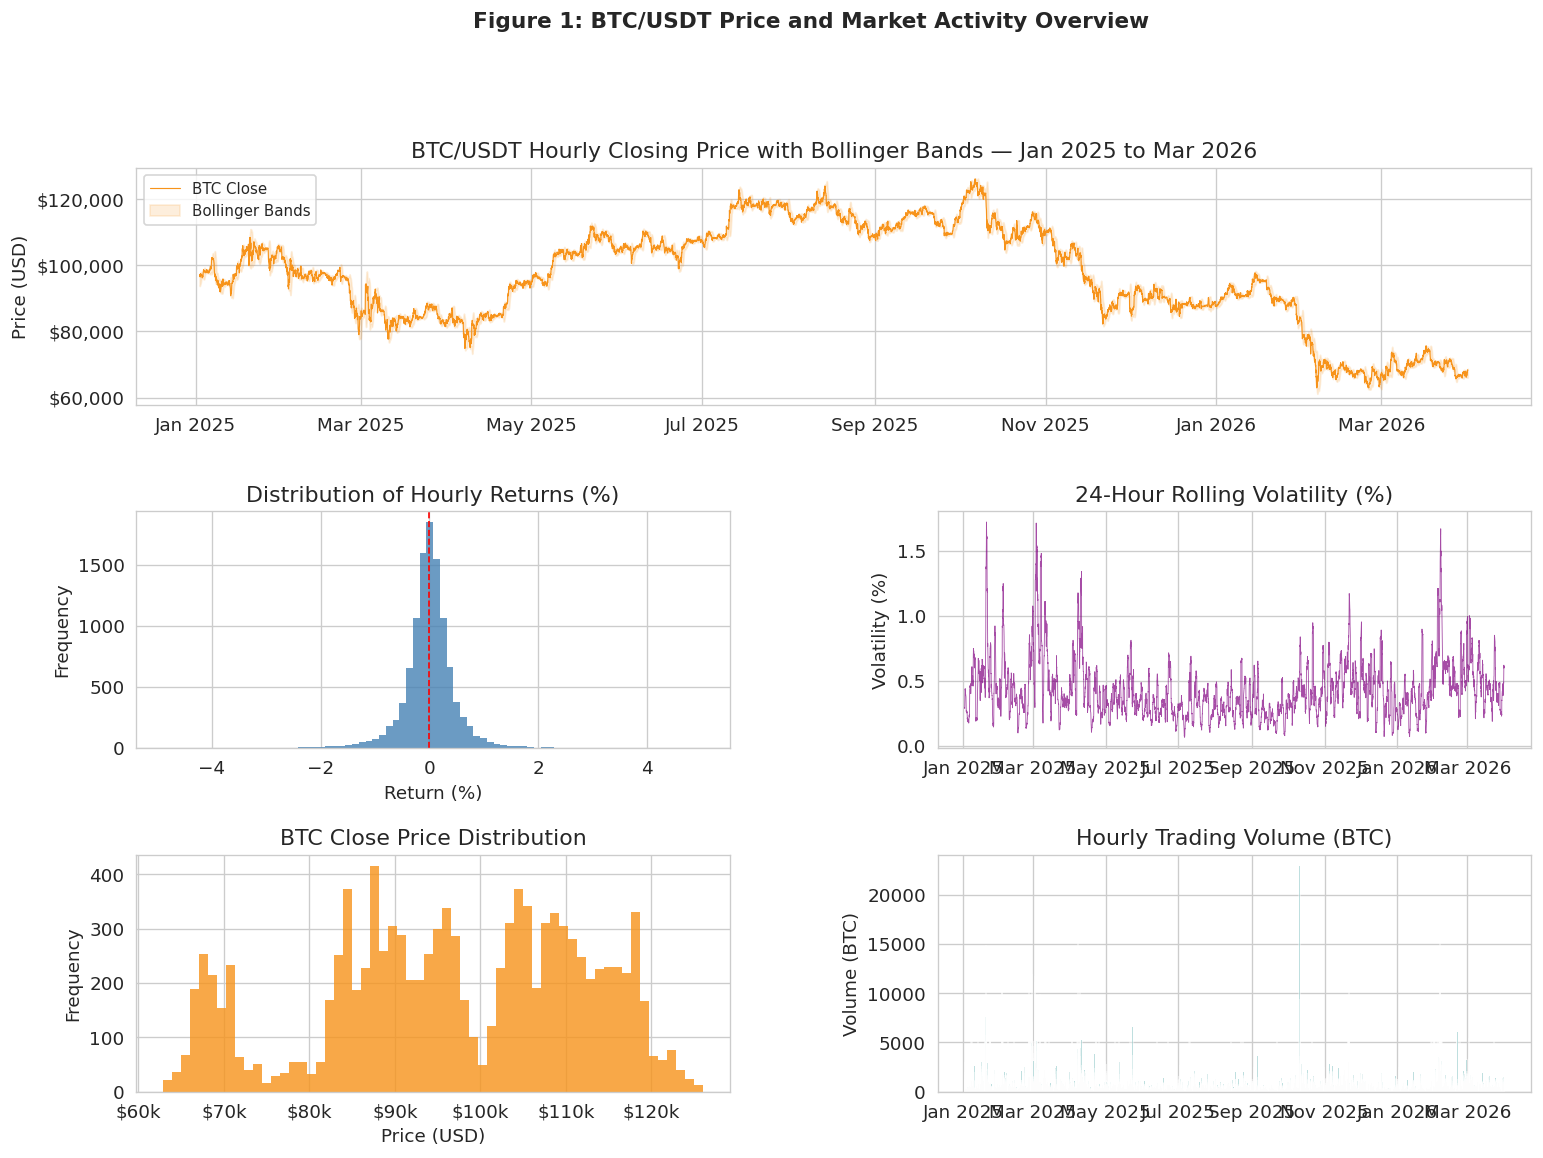

=== PRICE STATISTICS ===
count     10887.00
mean      96704.27
std       15218.97
min       62900.00
25%       86786.72
50%       96813.41
75%      109164.19
max      126011.18

Return stats (1h):
count    10887.0000
mean        -0.0019
std          0.4906
min         -4.8956
25%         -0.2025
50%          0.0010
75%          0.2104
max          5.0270


In [8]:
# ============================================================
# EDA CELL 2 — BTC Price Time Series + Returns Distribution
# ============================================================
fig = plt.figure(figsize=(15, 10))
gs = GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)

# 1. Price over time
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(df['timestamp'], df['close'], color='#F7931A', linewidth=0.7, label='BTC Close')
ax1.fill_between(df['timestamp'], df['bb_low'], df['bb_high'], alpha=0.15, color='#F7931A', label='Bollinger Bands')
ax1.set_title('BTC/USDT Hourly Closing Price with Bollinger Bands — Jan 2025 to Mar 2026')
ax1.set_ylabel('Price (USD)')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.legend(loc='upper left', fontsize=9)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))

# 2. Hourly returns distribution
ax2 = fig.add_subplot(gs[1, 0])
ax2.hist(df['return_1h'].dropna()*100, bins=80, color='steelblue', edgecolor='none', alpha=0.8)
ax2.axvline(0, color='red', linewidth=1, linestyle='--')
ax2.set_title('Distribution of Hourly Returns (%)')
ax2.set_xlabel('Return (%)'); ax2.set_ylabel('Frequency')

# 3. 24h volatility over time
ax3 = fig.add_subplot(gs[1, 1])
ax3.plot(df['timestamp'], df['volatility_24h']*100, color='purple', linewidth=0.5, alpha=0.7)
ax3.set_title('24-Hour Rolling Volatility (%)')
ax3.set_ylabel('Volatility (%)'); ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# 4. Price histogram
ax4 = fig.add_subplot(gs[2, 0])
ax4.hist(df['close'], bins=60, color='#F7931A', edgecolor='none', alpha=0.8)
ax4.set_title('BTC Close Price Distribution')
ax4.set_xlabel('Price (USD)'); ax4.set_ylabel('Frequency')
ax4.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))

# 5. Volume over time
ax5 = fig.add_subplot(gs[2, 1])
ax5.bar(df['timestamp'], df['volume'], width=0.04, color='teal', alpha=0.5)
ax5.set_title('Hourly Trading Volume (BTC)')
ax5.set_ylabel('Volume (BTC)'); ax5.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.suptitle('Figure 1: BTC/USDT Price and Market Activity Overview', fontsize=13, fontweight='bold', y=1.01)
plt.savefig('eda_price_overview.png', bbox_inches='tight')
plt.show()

# Print summary stats
print("=== PRICE STATISTICS ===")
print(df['close'].describe().round(2).to_string())
print(f"\nReturn stats (1h):\n{(df['return_1h']*100).describe().round(4).to_string()}")

=== TARGET LABEL DISTRIBUTION ===
Overall (all 10,887 rows):
  Up   (1): 5,450  (50.1%)
  Down (0): 5,437  (49.9%)


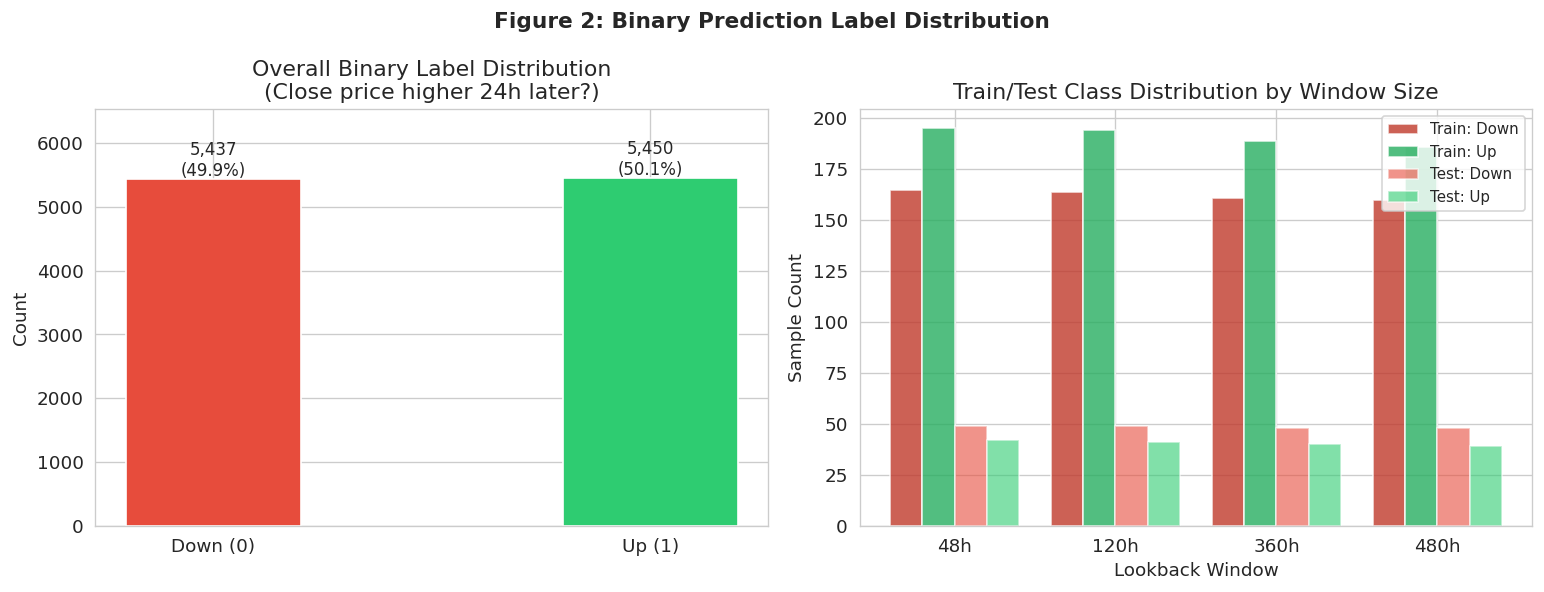

In [9]:
# ============================================================
# EDA CELL 3 — Label Distribution (Up/Down per Window)
# ============================================================
df['label_24h'] = (df['close'].shift(-24) > df['close']).astype(float)

print("=== TARGET LABEL DISTRIBUTION ===")
print(f"Overall (all {len(df.dropna(subset=['label_24h'])):,} rows):")
vc = df['label_24h'].dropna().value_counts()
print(f"  Up   (1): {vc[1]:,}  ({vc[1]/len(df.dropna(subset=['label_24h']))*100:.1f}%)")
print(f"  Down (0): {vc[0]:,}  ({vc[0]/len(df.dropna(subset=['label_24h']))*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Label distribution bar
axes[0].bar(['Down (0)', 'Up (1)'], [vc[0], vc[1]], color=['#e74c3c', '#2ecc71'], edgecolor='white', width=0.4)
axes[0].set_title('Overall Binary Label Distribution\n(Close price higher 24h later?)')
axes[0].set_ylabel('Count'); axes[0].set_ylim(0, max(vc)*1.2)
for i, v in enumerate([vc[0], vc[1]]):
    axes[0].text(i, v+50, f'{v:,}\n({v/sum(vc)*100:.1f}%)', ha='center', fontsize=10)

# Label distribution per window (in 80/20 split context)
windows = [48, 120, 360, 480]
train_up, train_down, test_up, test_down = [], [], [], []
step = 24; horizon = 24
for w in windows:
    X, y = [], []
    for i in range(w, len(df)-horizon+1, step):
        cur = df['close'].iloc[i-1]
        fut = df['close'].iloc[i+horizon-1]
        y.append(1 if fut > cur else 0)
    y = np.array(y)
    split = int(len(y)*0.8)
    train_up.append(y[:split].sum()); train_down.append((1-y[:split]).sum())
    test_up.append(y[split:].sum()); test_down.append((1-y[split:]).sum())

x = np.arange(len(windows)); width = 0.2
axes[1].bar(x-0.3, train_down, width, label='Train: Down', color='#c0392b', alpha=0.8)
axes[1].bar(x-0.1, train_up,   width, label='Train: Up',   color='#27ae60', alpha=0.8)
axes[1].bar(x+0.1, test_down,  width, label='Test: Down',  color='#e74c3c', alpha=0.6)
axes[1].bar(x+0.3, test_up,    width, label='Test: Up',    color='#2ecc71', alpha=0.6)
axes[1].set_xticks(x); axes[1].set_xticklabels([f'{w}h' for w in windows])
axes[1].set_title('Train/Test Class Distribution by Window Size')
axes[1].set_xlabel('Lookback Window'); axes[1].set_ylabel('Sample Count'); axes[1].legend(fontsize=9)

plt.suptitle('Figure 2: Binary Prediction Label Distribution', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('eda_labels.png', bbox_inches='tight'); plt.show()

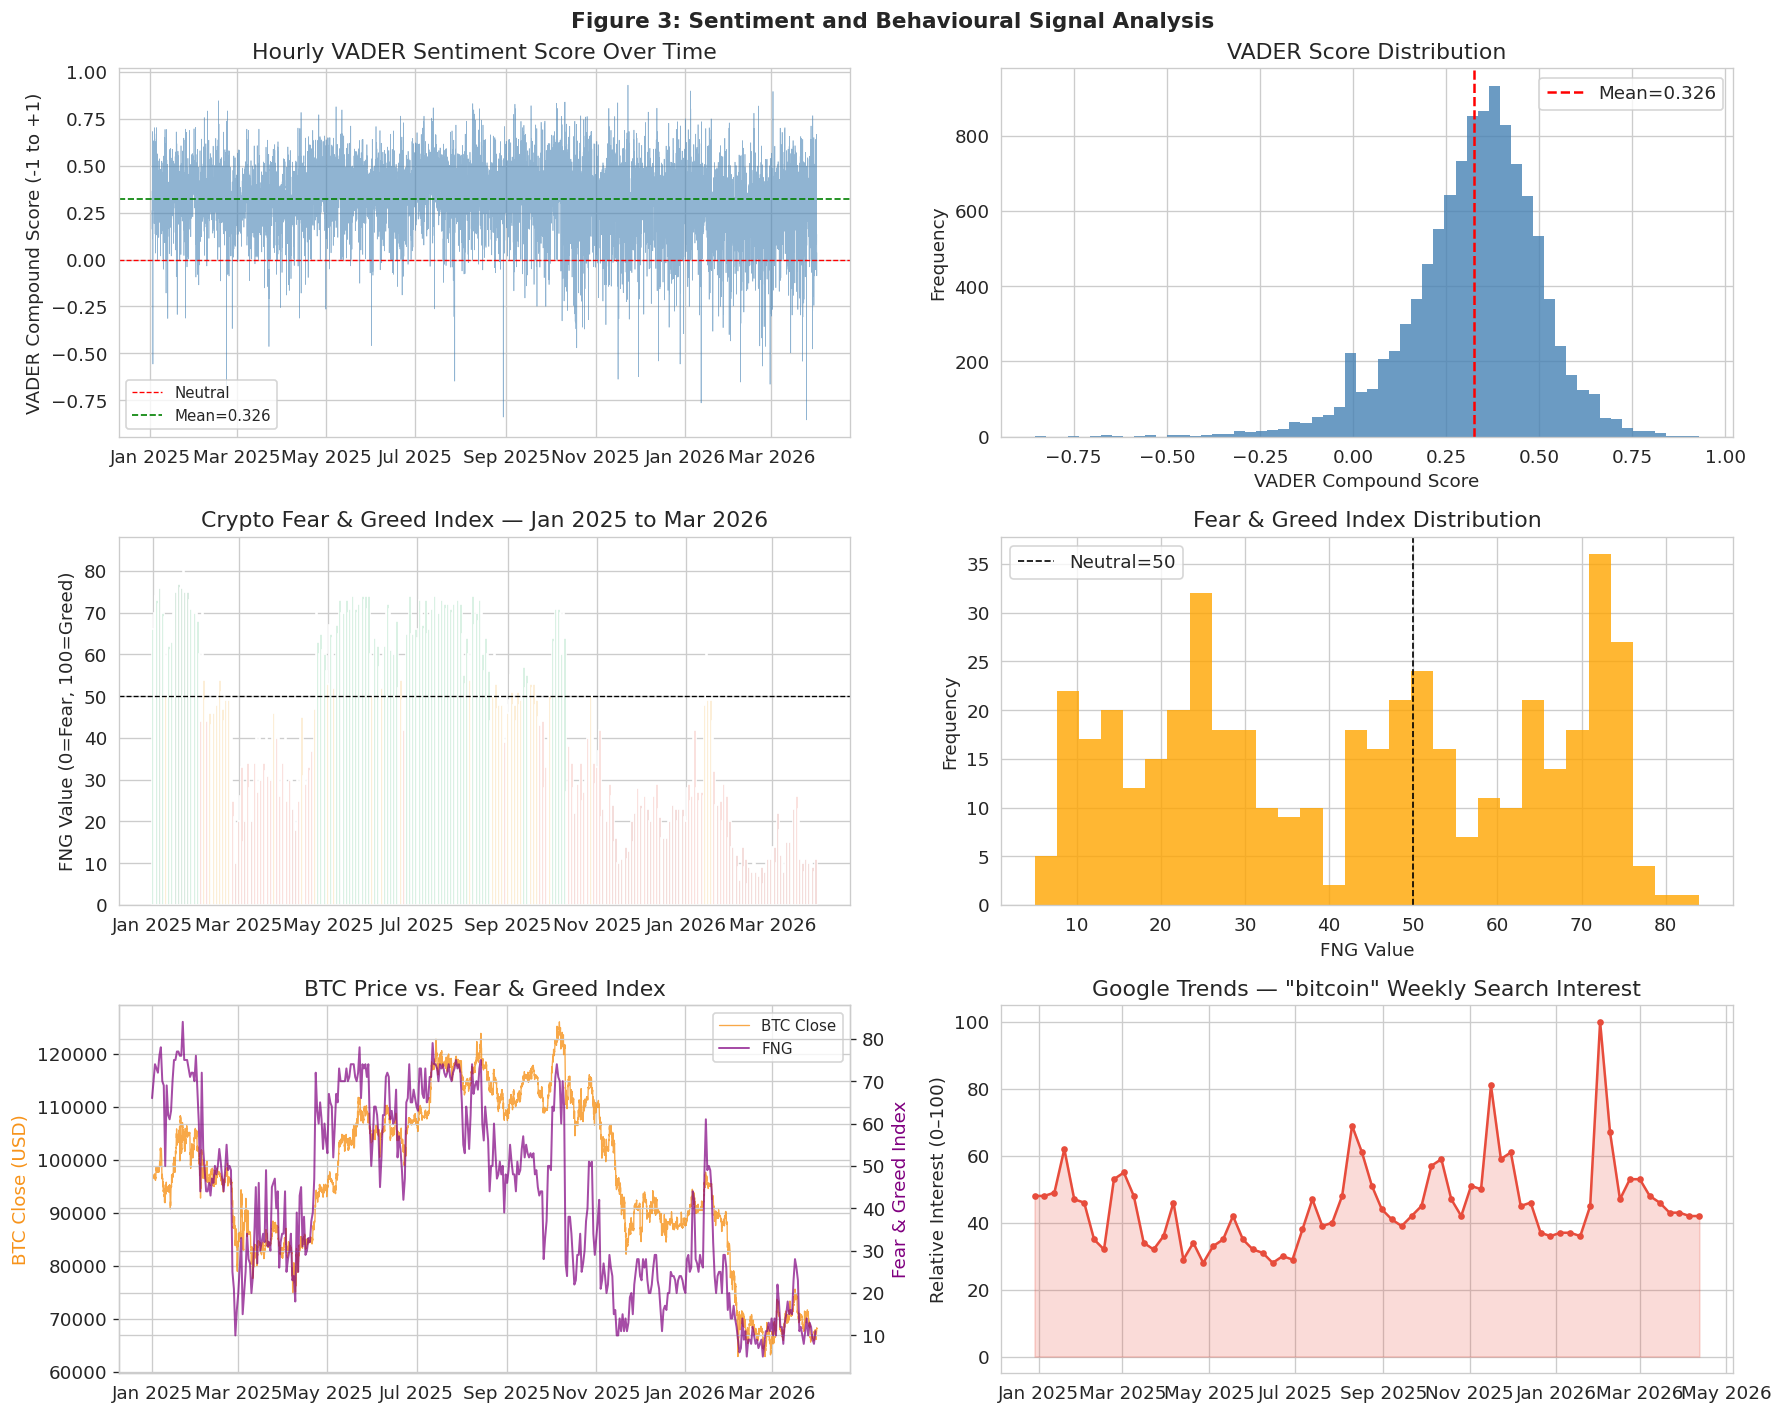

=== VADER STATISTICS ===
count    10887.0000
mean         0.3255
std          0.1751
min         -0.8553
25%          0.2327
50%          0.3443
75%          0.4380
max          0.9304

=== FEAR & GREED STATISTICS (Study Period) ===
count    455.00
mean      42.80
std       21.93
min        5.00
25%       24.00
50%       44.00
75%       64.00
max       84.00


In [10]:
# ============================================================
# EDA CELL 4 — VADER Sentiment + Fear & Greed Analysis
# ============================================================
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# 1. VADER over time
axes[0,0].plot(df['timestamp'], df['vader_sentiment'], color='steelblue', linewidth=0.4, alpha=0.6)
axes[0,0].axhline(0, color='red', linewidth=0.8, linestyle='--', label='Neutral')
axes[0,0].axhline(df['vader_sentiment'].mean(), color='green', linewidth=1, linestyle='--', label=f"Mean={df['vader_sentiment'].mean():.3f}")
axes[0,0].set_title('Hourly VADER Sentiment Score Over Time')
axes[0,0].set_ylabel('VADER Compound Score (-1 to +1)')
axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y')); axes[0,0].legend(fontsize=9)

# 2. VADER distribution
axes[0,1].hist(df['vader_sentiment'].dropna(), bins=60, color='steelblue', edgecolor='none', alpha=0.8)
axes[0,1].axvline(df['vader_sentiment'].mean(), color='red', linewidth=1.5, linestyle='--', label=f"Mean={df['vader_sentiment'].mean():.3f}")
axes[0,1].set_title('VADER Score Distribution')
axes[0,1].set_xlabel('VADER Compound Score'); axes[0,1].set_ylabel('Frequency'); axes[0,1].legend()

# 3. FNG over time (study period only)
fng_study = fng[(fng.timestamp >= '2025-01-01') & (fng.timestamp <= '2026-03-31')].copy()
colors = ['#c0392b' if v < 25 else '#e74c3c' if v < 45 else '#f39c12' if v < 55 else '#27ae60' if v < 75 else '#1e8449'
          for v in fng_study['fng_value']]
axes[1,0].bar(fng_study['timestamp'], fng_study['fng_value'], color=colors, width=1)
axes[1,0].axhline(50, color='black', linewidth=0.8, linestyle='--')
axes[1,0].set_title('Crypto Fear & Greed Index — Jan 2025 to Mar 2026')
axes[1,0].set_ylabel('FNG Value (0=Fear, 100=Greed)')
axes[1,0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

# 4. FNG distribution
axes[1,1].hist(fng_study['fng_value'], bins=30, color='orange', edgecolor='none', alpha=0.8)
axes[1,1].axvline(50, color='black', linewidth=1, linestyle='--', label='Neutral=50')
axes[1,1].set_title('Fear & Greed Index Distribution')
axes[1,1].set_xlabel('FNG Value'); axes[1,1].set_ylabel('Frequency'); axes[1,1].legend()

# 5. BTC price vs FNG (dual axis)
ax_price = axes[2,0]
ax_fng = ax_price.twinx()
ax_price.plot(df['timestamp'], df['close'], color='#F7931A', linewidth=0.8, alpha=0.8, label='BTC Close')
ax_fng.plot(fng_study['timestamp'], fng_study['fng_value'], color='purple', linewidth=1.2, alpha=0.7, label='FNG')
ax_price.set_ylabel('BTC Close (USD)', color='#F7931A')
ax_fng.set_ylabel('Fear & Greed Index', color='purple')
ax_price.set_title('BTC Price vs. Fear & Greed Index')
ax_price.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
lines1, labels1 = ax_price.get_legend_handles_labels()
lines2, labels2 = ax_fng.get_legend_handles_labels()
ax_price.legend(lines1+lines2, labels1+labels2, fontsize=9)

# 6. Google Trends
axes[2,1].plot(trends['timestamp'], trends['trend'], color='#e74c3c', linewidth=1.5, marker='o', markersize=3)
axes[2,1].fill_between(trends['timestamp'], trends['trend'], alpha=0.2, color='#e74c3c')
axes[2,1].set_title('Google Trends — "bitcoin" Weekly Search Interest')
axes[2,1].set_ylabel('Relative Interest (0–100)')
axes[2,1].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.suptitle('Figure 3: Sentiment and Behavioural Signal Analysis', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('eda_sentiment.png', bbox_inches='tight'); plt.show()

print("=== VADER STATISTICS ===")
print(df['vader_sentiment'].describe().round(4).to_string())
print(f"\n=== FEAR & GREED STATISTICS (Study Period) ===")
print(fng_study['fng_value'].describe().round(2).to_string())

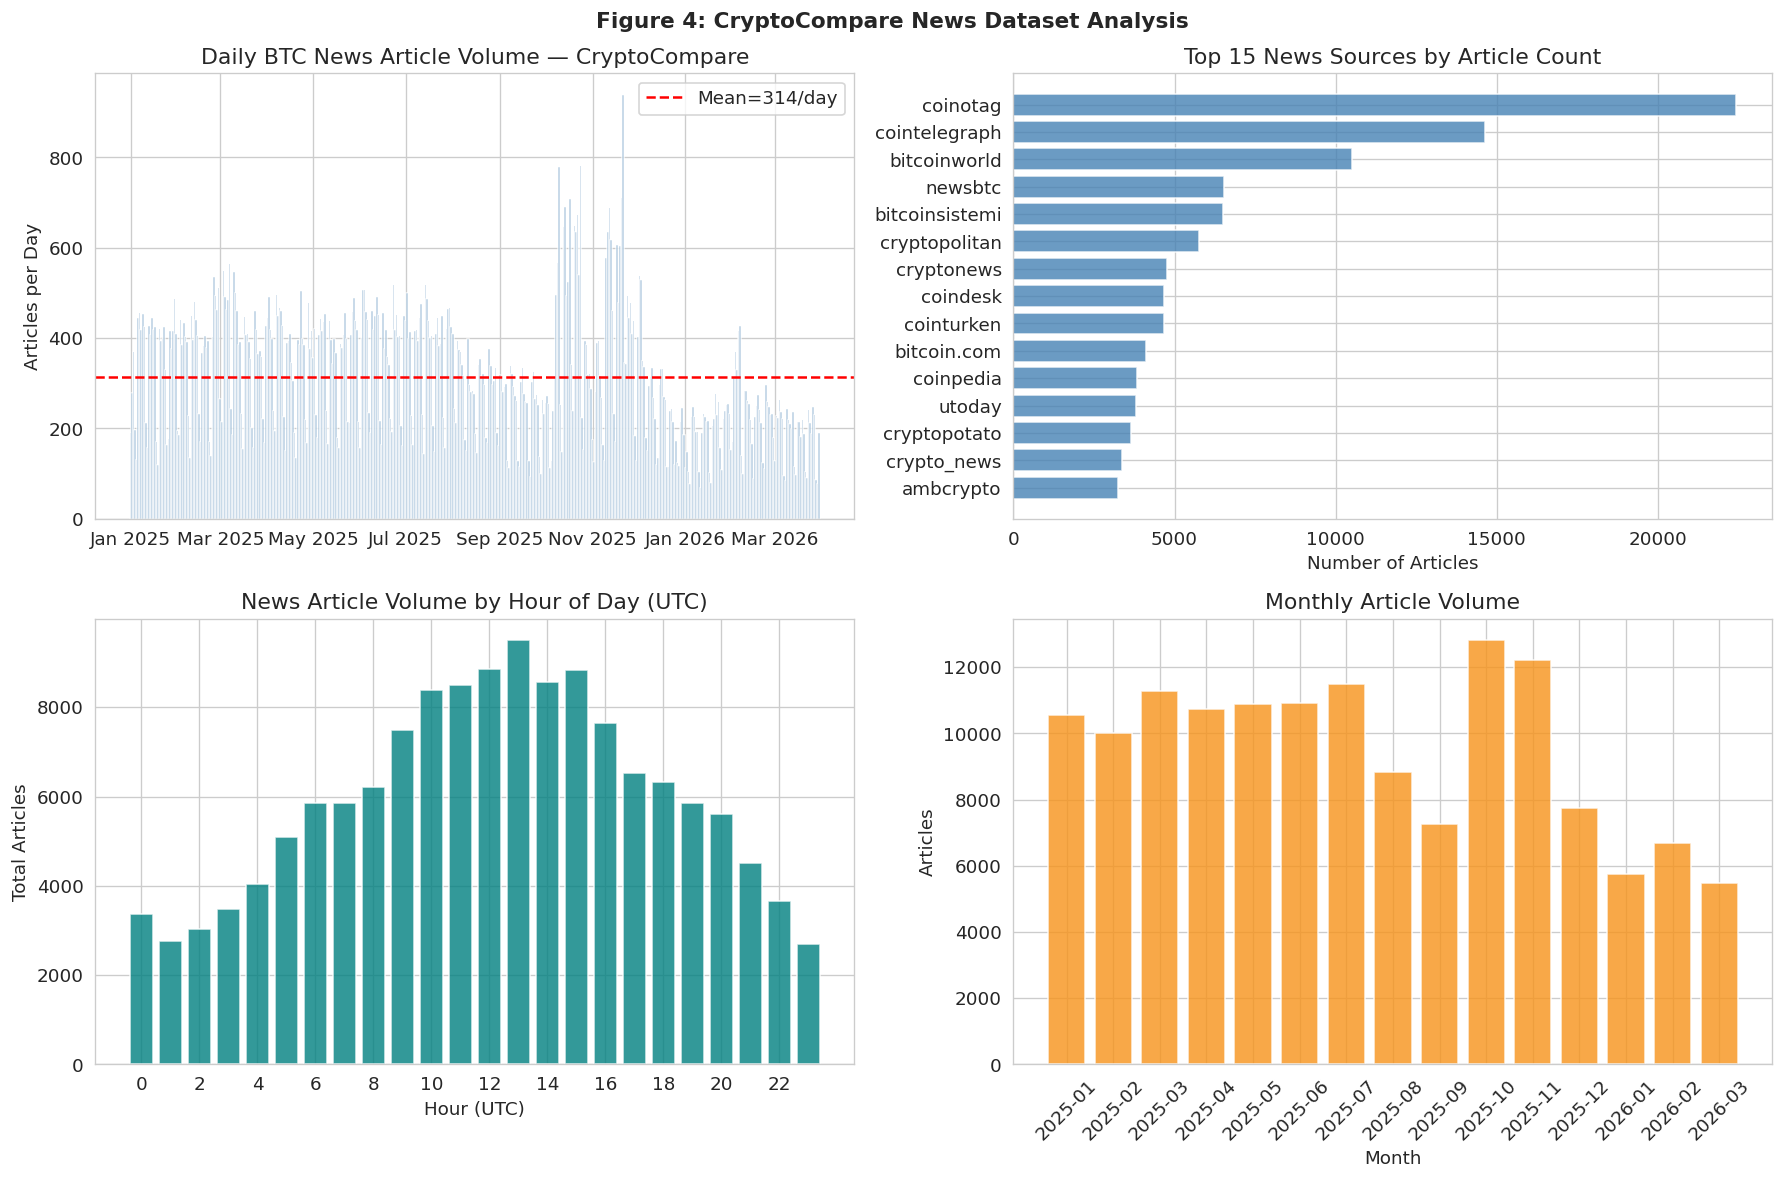

=== NEWS DATASET STATISTICS ===
Total articles      : 142,693
Unique sources      : 59
Date range          : 2025-01-01 → 2026-03-30
Avg articles/day    : 314.3
Max articles/day    : 939 on 2025-11-21
Min articles/day    : 69 on 2026-01-11

Top 10 sources:
source
coinotag          22438
cointelegraph     14641
bitcoinworld      10501
newsbtc            6522
bitcoinsistemi     6500
cryptopolitan      5749
cryptonews         4766
coindesk           4677
cointurken         4660
bitcoin.com        4117


In [11]:
# ============================================================
# EDA CELL 5 — News Source & Volume Analysis
# ============================================================
news_study = news[(news.timestamp >= '2025-01-01') & (news.timestamp <= '2026-03-31')].copy()
news_study['date'] = news_study['timestamp'].dt.date
daily_counts = news_study.groupby('date').size()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Daily article volume
axes[0,0].bar(pd.to_datetime(daily_counts.index), daily_counts.values, width=1, color='steelblue', alpha=0.7)
axes[0,0].set_title('Daily BTC News Article Volume — CryptoCompare')
axes[0,0].set_ylabel('Articles per Day')
axes[0,0].xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
axes[0,0].axhline(daily_counts.mean(), color='red', linewidth=1.5, linestyle='--', label=f'Mean={daily_counts.mean():.0f}/day')
axes[0,0].legend()

# 2. Top 15 sources
top_src = news_study['source'].value_counts().head(15)
axes[0,1].barh(top_src.index[::-1], top_src.values[::-1], color='steelblue', alpha=0.8)
axes[0,1].set_title('Top 15 News Sources by Article Count')
axes[0,1].set_xlabel('Number of Articles')

# 3. Articles per hour of day (UTC)
news_study['hour'] = news_study['timestamp'].dt.hour
hourly = news_study.groupby('hour').size()
axes[1,0].bar(hourly.index, hourly.values, color='teal', alpha=0.8)
axes[1,0].set_title('News Article Volume by Hour of Day (UTC)')
axes[1,0].set_xlabel('Hour (UTC)'); axes[1,0].set_ylabel('Total Articles')
axes[1,0].set_xticks(range(0, 24, 2))

# 4. Articles per month
news_study['month'] = news_study['timestamp'].dt.to_period('M')
monthly = news_study.groupby('month').size()
axes[1,1].bar(monthly.index.astype(str), monthly.values, color='#F7931A', alpha=0.8)
axes[1,1].set_title('Monthly Article Volume')
axes[1,1].set_xlabel('Month'); axes[1,1].set_ylabel('Articles')
axes[1,1].tick_params(axis='x', rotation=45)

plt.suptitle('Figure 4: CryptoCompare News Dataset Analysis', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('eda_news.png', bbox_inches='tight'); plt.show()

print("=== NEWS DATASET STATISTICS ===")
print(f"Total articles      : {len(news_study):,}")
print(f"Unique sources      : {news_study['source'].nunique()}")
print(f"Date range          : {news_study.timestamp.min().date()} → {news_study.timestamp.max().date()}")
print(f"Avg articles/day    : {daily_counts.mean():.1f}")
print(f"Max articles/day    : {daily_counts.max()} on {daily_counts.idxmax()}")
print(f"Min articles/day    : {daily_counts.min()} on {daily_counts.idxmin()}")
print(f"\nTop 10 sources:\n{top_src.head(10).to_string()}")

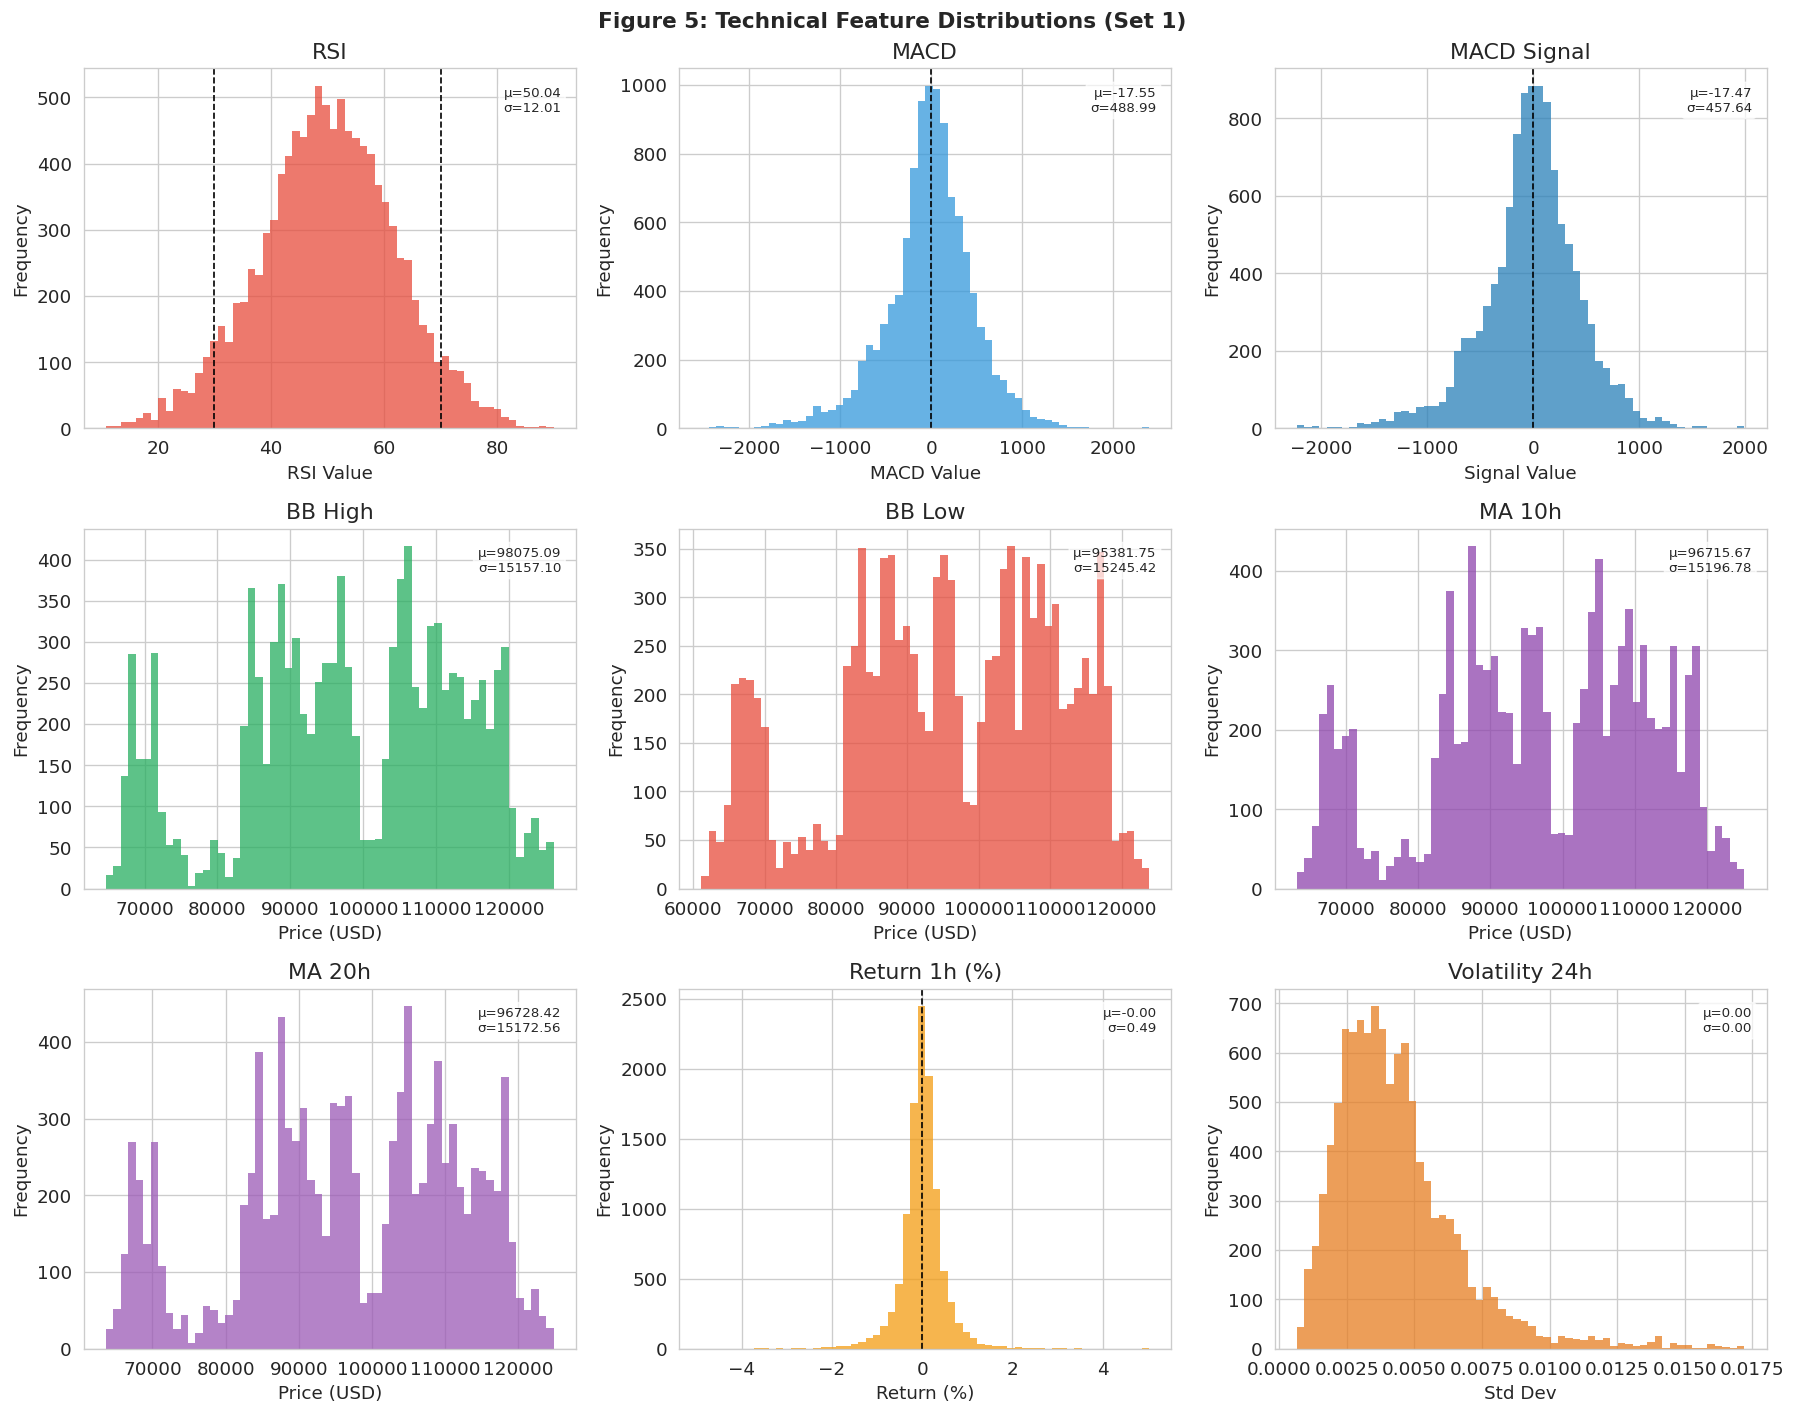

In [12]:
# ============================================================
# EDA CELL 6 — Technical Indicator Distributions
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

indicators = {
    'RSI': ('rsi', '#e74c3c', [30, 70], 'RSI Value'),
    'MACD': ('macd', '#3498db', [0], 'MACD Value'),
    'MACD Signal': ('macd_signal', '#2980b9', [0], 'Signal Value'),
    'BB High': ('bb_high', '#27ae60', None, 'Price (USD)'),
    'BB Low': ('bb_low', '#e74c3c', None, 'Price (USD)'),
    'MA 10h': ('ma_10', '#8e44ad', None, 'Price (USD)'),
    'MA 20h': ('ma_20', '#9b59b6', None, 'Price (USD)'),
    'Return 1h (%)': ('return_1h', '#f39c12', [0], 'Return (%)'),
    'Volatility 24h': ('volatility_24h', '#e67e22', None, 'Std Dev'),
}

for ax, (label, (col, color, vlines, xlabel)) in zip(axes.flatten(), indicators.items()):
    data = df[col].dropna()
    if col == 'return_1h':
        data = data * 100
    ax.hist(data, bins=60, color=color, edgecolor='none', alpha=0.75)
    if vlines:
        for vl in vlines:
            ax.axvline(vl, color='black', linewidth=1, linestyle='--')
    ax.set_title(label); ax.set_xlabel(xlabel); ax.set_ylabel('Frequency')
    ax.text(0.97, 0.95, f'μ={data.mean():.2f}\nσ={data.std():.2f}',
            transform=ax.transAxes, ha='right', va='top', fontsize=8,
            bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.7))

plt.suptitle('Figure 5: Technical Feature Distributions (Set 1)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('eda_indicators.png', bbox_inches='tight'); plt.show()

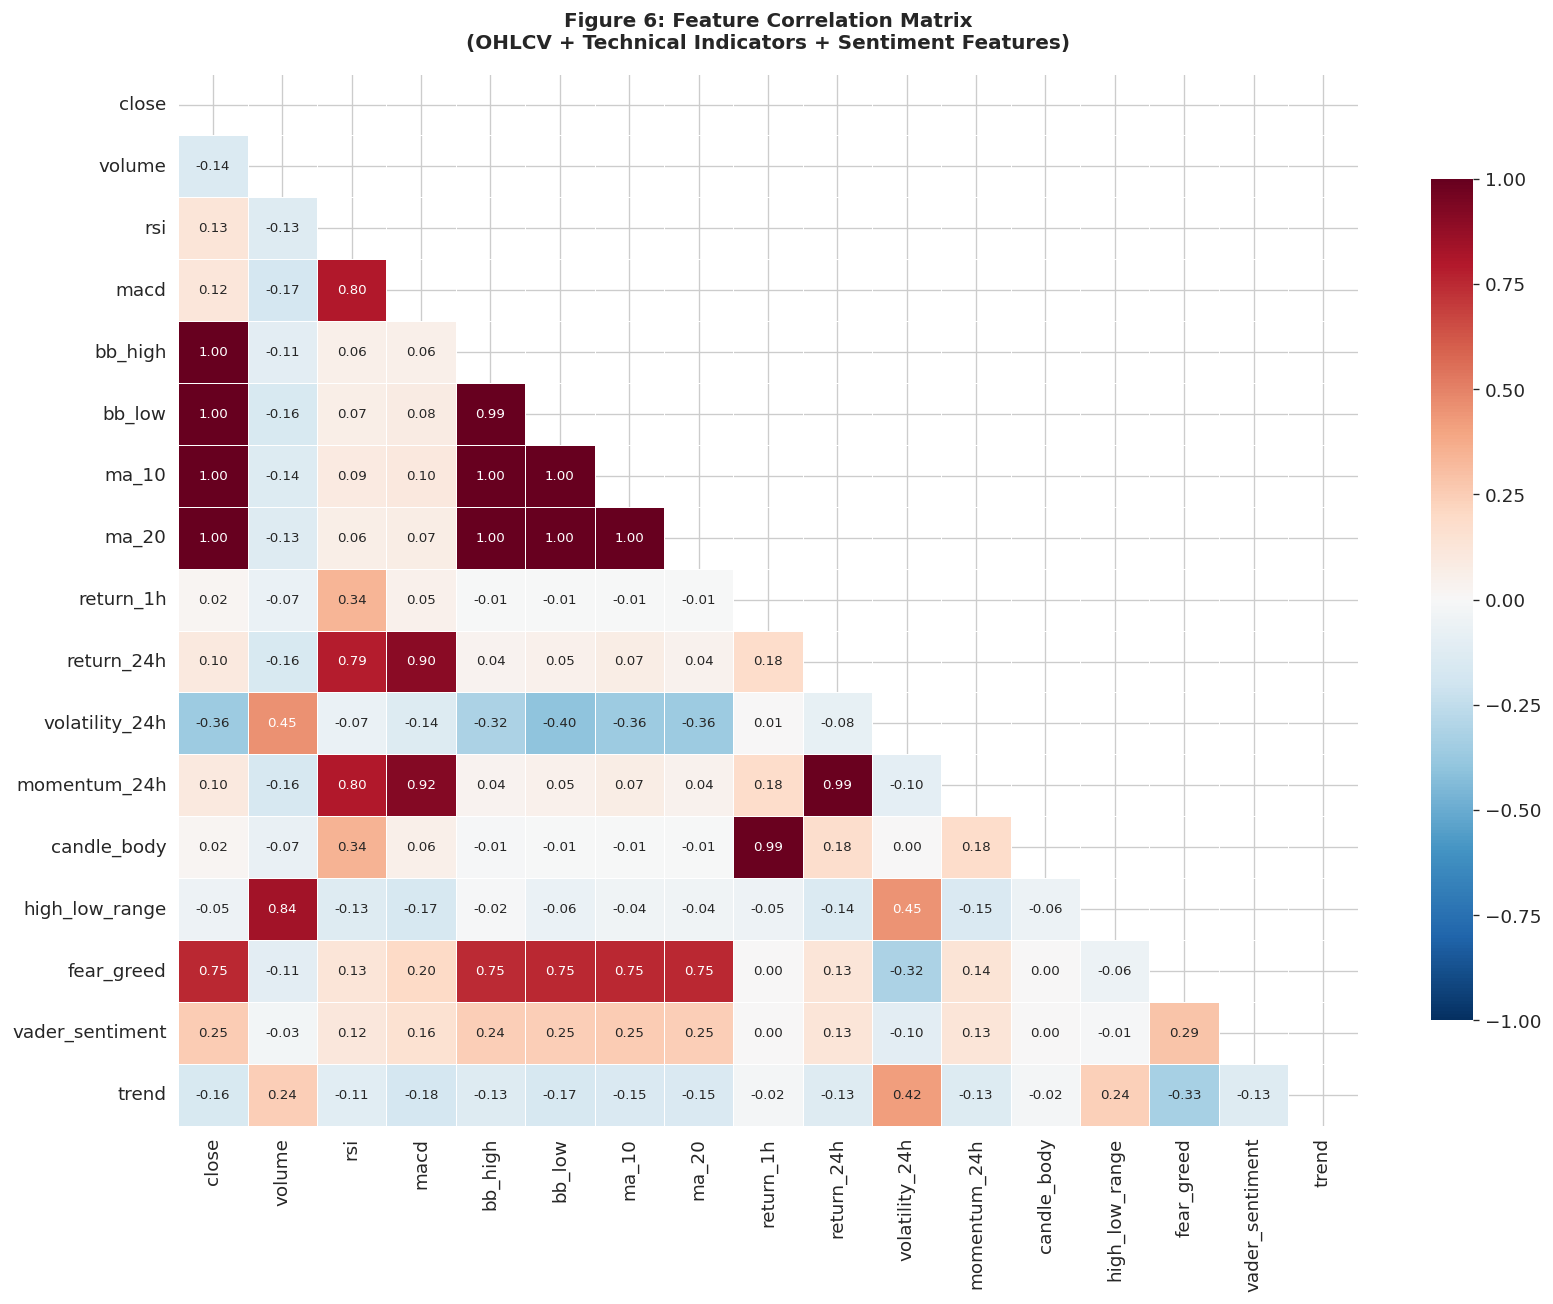

=== HIGH CORRELATIONS (|r| > 0.7) ===
  close                ↔ bb_high               r=0.995
  close                ↔ bb_low                r=0.996
  close                ↔ ma_10                 r=0.999
  close                ↔ ma_20                 r=0.997
  close                ↔ fear_greed            r=0.753
  volume               ↔ high_low_range        r=0.842
  rsi                  ↔ macd                  r=0.800
  rsi                  ↔ return_24h            r=0.789
  rsi                  ↔ momentum_24h          r=0.804
  macd                 ↔ return_24h            r=0.903
  macd                 ↔ momentum_24h          r=0.918
  bb_high              ↔ bb_low                r=0.992
  bb_high              ↔ ma_10                 r=0.997
  bb_high              ↔ ma_20                 r=0.998
  bb_high              ↔ fear_greed            r=0.746
  bb_low               ↔ ma_10                 r=0.998
  bb_low               ↔ ma_20                 r=0.998
  bb_low               ↔ fe

In [13]:
# ============================================================
# EDA CELL 7 — Feature Correlation Heatmap
# ============================================================
corr_cols = ['close', 'volume', 'rsi', 'macd', 'bb_high', 'bb_low', 'ma_10', 'ma_20',
             'return_1h', 'return_24h', 'volatility_24h', 'momentum_24h',
             'candle_body', 'high_low_range', 'fear_greed', 'vader_sentiment', 'trend']

corr = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            linewidths=0.4, annot_kws={'size': 8}, vmin=-1, vmax=1, ax=ax,
            cbar_kws={'shrink': 0.8})
ax.set_title('Figure 6: Feature Correlation Matrix\n(OHLCV + Technical Indicators + Sentiment Features)',
             fontsize=12, fontweight='bold', pad=15)
plt.tight_layout(); plt.savefig('eda_correlation.png', bbox_inches='tight'); plt.show()

# Print high correlations (|r| > 0.7, excluding self)
print("=== HIGH CORRELATIONS (|r| > 0.7) ===")
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        r = corr.iloc[i,j]
        if abs(r) > 0.7:
            print(f"  {corr.columns[i]:20s} ↔ {corr.columns[j]:20s}  r={r:.3f}")

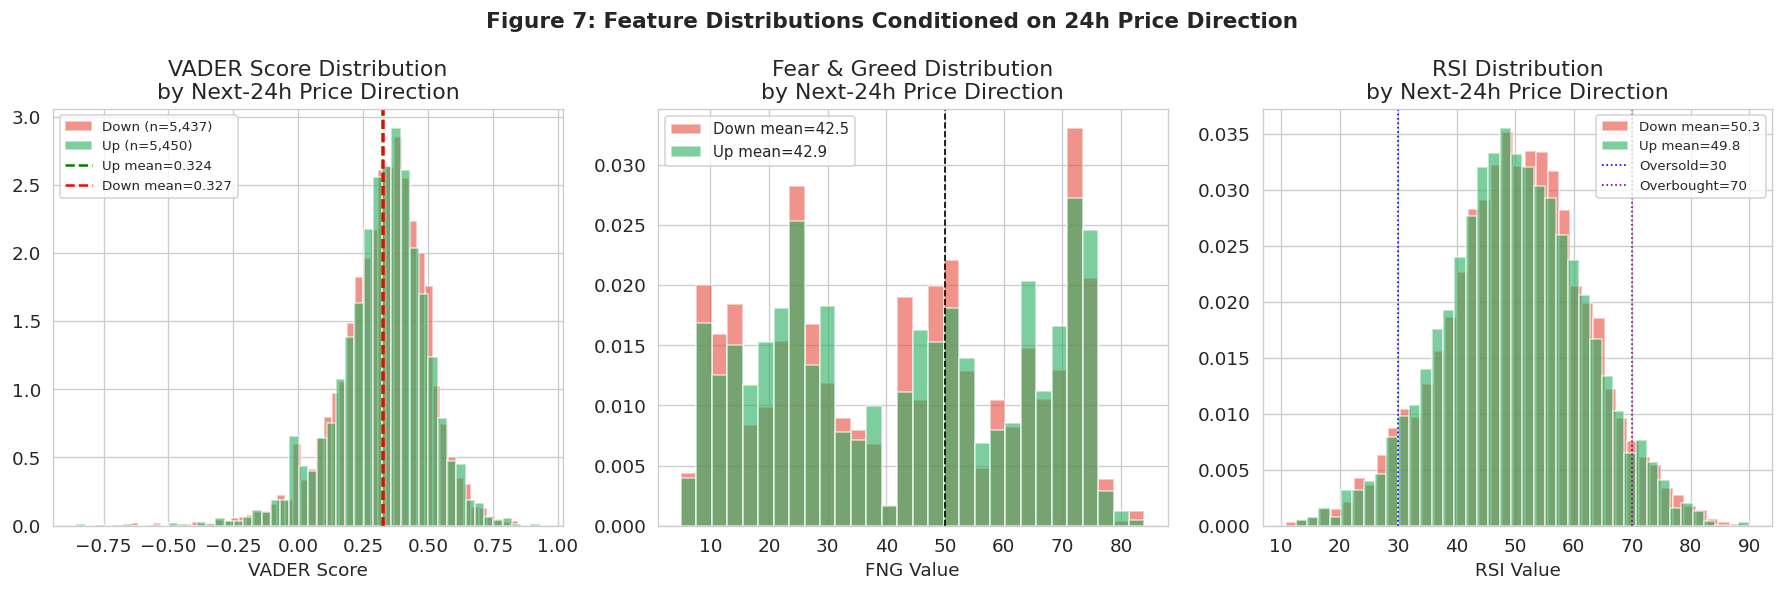

=== MEAN FEATURE VALUES BY LABEL ===
       vader_sentiment  fear_greed      rsi  return_1h  volatility_24h
label                                                                 
0.0             0.3271     42.5047  50.2850     0.0001          0.0044
1.0             0.3239     42.9431  49.7936    -0.0001          0.0043


In [14]:
# ============================================================
# EDA CELL 8 — VADER vs Price Movement (Key Thesis Insight)
# ============================================================
df['label'] = (df['close'].shift(-24) > df['close']).astype(float)
df_clean = df.dropna(subset=['label', 'vader_sentiment', 'fear_greed'])

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. VADER score by label
up = df_clean[df_clean['label']==1]['vader_sentiment']
down = df_clean[df_clean['label']==0]['vader_sentiment']
axes[0].hist(down, bins=50, alpha=0.6, color='#e74c3c', label=f'Down (n={len(down):,})', density=True)
axes[0].hist(up, bins=50, alpha=0.6, color='#27ae60', label=f'Up (n={len(up):,})', density=True)
axes[0].axvline(up.mean(), color='green', linestyle='--', linewidth=1.5, label=f'Up mean={up.mean():.3f}')
axes[0].axvline(down.mean(), color='red', linestyle='--', linewidth=1.5, label=f'Down mean={down.mean():.3f}')
axes[0].set_title('VADER Score Distribution\nby Next-24h Price Direction')
axes[0].set_xlabel('VADER Score'); axes[0].legend(fontsize=8)

# 2. FNG by label
up_fng = df_clean[df_clean['label']==1]['fear_greed']
down_fng = df_clean[df_clean['label']==0]['fear_greed']
axes[1].hist(down_fng, bins=30, alpha=0.6, color='#e74c3c', label=f'Down mean={down_fng.mean():.1f}', density=True)
axes[1].hist(up_fng, bins=30, alpha=0.6, color='#27ae60', label=f'Up mean={up_fng.mean():.1f}', density=True)
axes[1].axvline(50, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Fear & Greed Distribution\nby Next-24h Price Direction')
axes[1].set_xlabel('FNG Value'); axes[1].legend(fontsize=9)

# 3. RSI by label
up_rsi = df_clean[df_clean['label']==1]['rsi']
down_rsi = df_clean[df_clean['label']==0]['rsi']
axes[2].hist(down_rsi, bins=40, alpha=0.6, color='#e74c3c', label=f'Down mean={down_rsi.mean():.1f}', density=True)
axes[2].hist(up_rsi, bins=40, alpha=0.6, color='#27ae60', label=f'Up mean={up_rsi.mean():.1f}', density=True)
axes[2].axvline(30, color='blue', linestyle=':', linewidth=1, label='Oversold=30')
axes[2].axvline(70, color='purple', linestyle=':', linewidth=1, label='Overbought=70')
axes[2].set_title('RSI Distribution\nby Next-24h Price Direction')
axes[2].set_xlabel('RSI Value'); axes[2].legend(fontsize=8)

plt.suptitle('Figure 7: Feature Distributions Conditioned on 24h Price Direction', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.savefig('eda_feature_vs_label.png', bbox_inches='tight'); plt.show()

print("=== MEAN FEATURE VALUES BY LABEL ===")
print(df_clean.groupby('label')[['vader_sentiment','fear_greed','rsi','return_1h','volatility_24h']].mean().round(4).to_string())